<a href="https://colab.research.google.com/github/Dheena2411/CRM-CM-CW1/blob/task2_clustering/CRM%26CM_CW1_T1_T2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1- Data Preparation & Feature Engineering

#### Task 1 – Data preparation. Built on the 6BUIS017W tutorial notebook SP500_RFM_Analysis_2022_2024. Changes made to meet the brief: extended period to 2021, removed forward/backward filling, excluded partial weeks, added volume-based RFM, cached snapshots and provenance metadata.

In [53]:
!pip install -q yfinance lxml

import sys, pandas as pd, numpy as np, yfinance as yf
import sklearn, scipy, matplotlib
import os, time

print("Python", sys.version.split()[0])
for m in [pd, np, yf, sklearn, scipy, matplotlib]:
    print(m.__name__, m.__version__)

Python 3.13.18
pandas 2.2.3
numpy 2.4.6
yfinance 0.2.66
sklearn 1.6.1
scipy 1.16.3
matplotlib 3.10.0


In [54]:
START_DATE = "2021-01-01"   # inclusive
END_DATE   = "2025-01-01"   # exclusive, so the last trading day is 31 Dec 2024
BENCHMARK  = "^GSPC"
RETRIEVAL_DATE = pd.Timestamp.today().strftime("%Y-%m-%d")  # record this in the report
print("Data retrieved on:", RETRIEVAL_DATE)

Data retrieved on: 2026-11-21


## Task 1.1- Ticker selection and data acquisition

In [55]:
# Part 1: S&P 500 constituents from Wikipedia
# Adapted from the tutorial notebook (SP500_RFM_Analysis_2022_2024).
# Change: saved snapshots are loaded first (local, then GitHub), so the
# constituent list and retrieval date stay fixed whenever the notebook is re-run.
import os, json

WIKI_URL    = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
GITHUB_RAW  = "https://raw.githubusercontent.com/Dheena2411/CRM-CM-CW1/task1_data_prep/data/"
TICKER_FILE = "sp500_tickers.csv"

def load_snapshot(filename, reader):
    """Try the local Colab copy, then the copy preserved on GitHub.
    Returns None if neither exists, so the caller can download fresh data."""
    if os.path.exists(filename):
        print(f"Loaded local snapshot: {filename}")
        return reader(filename)
    try:
        df = reader(GITHUB_RAW + filename)
        print(f"Loaded snapshot from GitHub: {filename}")
        return df
    except Exception:
        return None

sp500 = load_snapshot(TICKER_FILE, pd.read_csv)

if sp500 is not None:
    RETRIEVAL_DATE = sp500["retrieval_date"].iloc[0]        # keep the ORIGINAL date
else:
    print("No saved ticker list found - retrieving from Wikipedia")
    sp500 = pd.read_html(WIKI_URL, match="Symbol",
                         storage_options={"User-Agent": "Mozilla/5.0"})[0]
    sp500["yf_ticker"] = sp500["Symbol"].str.replace(".", "-", regex=False)
    sp500["retrieval_date"] = RETRIEVAL_DATE
    sp500.to_csv(TICKER_FILE, index=False)

assert sp500["yf_ticker"].is_unique, "Duplicate tickers found"
print(f"Total tickers: {len(sp500)} | retrieved on {RETRIEVAL_DATE}")
sp500[["Symbol", "yf_ticker", "Security", "GICS Sector"]].head(10)

Loaded snapshot from GitHub: sp500_tickers.csv
Total tickers: 503 | retrieved on 2026-11-20


,Symbol,yf_ticker,Security,GICS Sector
0,MMM,MMM,3M,Industrials
1,AOS,AOS,A. O. Smith,Industrials
2,ABT,ABT,Abbott Laboratories,Health Care
3,ABBV,ABBV,AbbVie,Health Care
4,ACN,ACN,Accenture,Information Technology
5,ADBE,ADBE,Adobe Inc.,Information Technology
6,AMD,AMD,Advanced Micro Devices,Information Technology
7,AES,AES,AES Corporation,Utilities
8,AFL,AFL,Aflac,Financials
9,A,A,Agilent Technologies,Health Care


In [56]:
import time

DATA_FILE = "sp500_daily_2021_2024.parquet"
META_FILE = "download_metadata.json"
tickers = sp500["yf_ticker"].tolist() + [BENCHMARK]

def download_batch(batch, retries=3):
    for attempt in range(retries):
        try:
            return yf.download(batch, start=START_DATE, end=END_DATE,
                               auto_adjust=False, actions=True,
                               group_by="column", threads=True, progress=False)
        except Exception as e:
            print(f"  Attempt {attempt+1} failed: {e}")
            time.sleep(5)
    raise RuntimeError(f"Batch failed after {retries} attempts: {batch[:3]}...")

prices = load_snapshot(DATA_FILE, pd.read_parquet)

if prices is None:
    print("No saved price snapshot found - downloading from Yahoo Finance")
    frames = []
    for i in range(0, len(tickers), 50):
        batch = tickers[i:i+50]
        long = download_batch(batch).stack(level=1, future_stack=True)
        long.index.names = ["Date", "Ticker"]
        frames.append(long.reset_index())
        print(f"Batch {i//50 + 1} done ({len(batch)} tickers)")
        time.sleep(2)
    prices = pd.concat(frames, ignore_index=True)
    prices.columns.name = None
    prices.to_parquet(DATA_FILE, index=False)

    meta = {
        "ticker_source": WIKI_URL,
        "ticker_retrieval_date": RETRIEVAL_DATE,
        "price_source": "Yahoo Finance via yfinance",
        "yfinance_version": yf.__version__,
        "pandas_version": pd.__version__,
        "download_timestamp": pd.Timestamp.now().isoformat(timespec="seconds"),
        "start_date": START_DATE, "end_date_exclusive": END_DATE,
        "benchmark": BENCHMARK, "auto_adjust": False,
        "n_tickers_requested": len(tickers),
    }
    with open(META_FILE, "w") as f:
        json.dump(meta, f, indent=2)

prices.head()

Loaded snapshot from GitHub: sp500_daily_2021_2024.parquet


,Date,Ticker,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
0,2021-01-04,A,114.009109,118.639999,0.194,120.089996,117.110001,118.940002,0.0,2030700.0
1,2021-01-04,AAPL,125.537094,129.410004,0.000,133.610001,126.760002,133.520004,0.0,143301900.0
2,2021-01-04,ABBV,84.219147,105.410004,0.000,107.349998,103.860001,107.180000,0.0,9523400.0
3,2021-01-04,ABNB,139.149994,139.149994,0.000,151.005005,137.000000,150.990005,0.0,6409900.0
4,2021-01-04,ABT,97.269707,109.110001,0.000,110.250000,107.260002,109.529999,0.0,6192000.0


In [57]:
got = prices.dropna(subset=["Adj Close"])["Ticker"].unique()
failed = sorted(set(tickers) - set(got))

print("Total rows:", len(prices))
print("Tickers with data:", len(got), "of", len(tickers))
print("Date range:", prices["Date"].min().date(), "to", prices["Date"].max().date())
print("Failed downloads:", failed)

Total rows: 506520
Tickers with data: 499 of 504
Date range: 2021-01-04 to 2024-12-31
Failed downloads: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


In [58]:
# Export helper: only exports files that exist locally (i.e. after a fresh download).
# When snapshots are loaded from GitHub there is nothing new to export.
from google.colab import files

for f in [DATA_FILE, TICKER_FILE, META_FILE]:
    if os.path.exists(f):
        print(f"{f}: {os.path.getsize(f) / 1e6:.1f} MB - downloading")
        files.download(f)
    else:
        print(f"{f}: loaded from GitHub snapshot, nothing to export")

sp500_daily_2021_2024.parquet: loaded from GitHub snapshot, nothing to export
sp500_tickers.csv: loaded from GitHub snapshot, nothing to export
download_metadata.json: loaded from GitHub snapshot, nothing to export


## Task 1.2: Data validation and exclusion log

#### 1.2 Data validation. The tutorial forward- and back-filled missing prices; the brief prohibits silent filling, so shares failing any rule below are excluded and logged instead. Rules: (1) data returned, (2) full history from the first to the last benchmark trading day, (3) no missing Adj Close, Close or Volume on any benchmark trading day, (4) no non-positive prices, (5) no zero or negative volume. Corporate actions are flagged for checking.

In [59]:
prices["Date"] = pd.to_datetime(prices["Date"])
prices = prices.sort_values(["Ticker", "Date"]).reset_index(drop=True)

# The benchmark's trading days define the official calendar for the study
bench = prices[prices["Ticker"] == BENCHMARK].dropna(subset=["Adj Close"]).set_index("Date")
calendar = bench.index
FIRST_DAY, LAST_DAY = calendar.min(), calendar.max()
print(f"Benchmark trading days: {len(calendar)} | {FIRST_DAY.date()} to {LAST_DAY.date()}")

shares = prices[prices["Ticker"] != BENCHMARK].copy()

# Duplicate check (same ticker + same date)
dups = shares.duplicated(["Ticker", "Date"]).sum()
print("Duplicate ticker-date rows:", dups)
shares = shares.drop_duplicates(["Ticker", "Date"], keep="first")

Benchmark trading days: 1005 | 2021-01-04 to 2024-12-31
Duplicate ticker-date rows: 0


In [60]:
def validate_share(g):
    g = g.set_index("Date").reindex(calendar)       # align to benchmark calendar, no filling
    valid = g["Adj Close"].dropna()
    return pd.Series({
        "first_valid":       valid.index.min() if len(valid) else pd.NaT,
        "last_valid":        valid.index.max() if len(valid) else pd.NaT,
        "valid_days":        len(valid),
        "missing_adj_close": int(g["Adj Close"].isna().sum()),
        "missing_close":     int(g["Close"].isna().sum()),
        "missing_volume":    int(g["Volume"].isna().sum()),
        "nonpositive_price": int(((g["Close"] <= 0) | (g["Adj Close"] <= 0)).sum()),
        "negative_volume":   int((g["Volume"] < 0).sum()),
        "zero_volume_days":  int((g["Volume"] == 0).sum()),
        "split_events":      int((g["Stock Splits"].fillna(0) > 0).sum()),
        "dividend_events":   int((g["Dividends"].fillna(0) > 0).sum()),
        "max_abs_daily_move": g["Close"].pct_change(fill_method=None).abs().max(),
    })

checks = shares.groupby("Ticker").apply(validate_share)

def exclusion_reason(r):
    if r.valid_days == 0:
        return "No price data (not separately listed during study period)"
    if r.first_valid > FIRST_DAY or r.last_valid < LAST_DAY:
        return f"Incomplete history ({r.first_valid.date()} to {r.last_valid.date()})"
    if r.missing_adj_close or r.missing_close or r.missing_volume:
        return "Missing values on benchmark trading days"
    if r.nonpositive_price:
        return "Non-positive price"
    if r.negative_volume or r.zero_volume_days:
        return "Volume error (zero or negative)"
    return None

checks["exclusion_reason"] = checks.apply(exclusion_reason, axis=1)
checks["included"] = checks["exclusion_reason"].isna()

print(f"Shares checked: {len(checks)} | Included: {checks['included'].sum()} | Excluded: {(~checks['included']).sum()}")
checks["exclusion_reason"].str.split(" \\(").str[0].value_counts()

Shares checked: 503 | Included: 486 | Excluded: 17


/tmp/ipykernel_1734/1686217991.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  checks = shares.groupby("Ticker").apply(validate_share)


,count
exclusion_reason,
Incomplete history,10
No price data,5
Volume error,2


In [61]:
exclusion_log = (checks.loc[~checks["included"], ["exclusion_reason", "first_valid", "last_valid", "valid_days"]]
                 .reset_index())
exclusion_log.to_csv("exclusion_log.csv", index=False)
display(exclusion_log)

# Corporate actions: yfinance's Close is split-adjusted, so a split day should NOT
# show a huge price jump. A large move on a split day suggests an unadjusted split.
splits = shares[shares["Stock Splits"].fillna(0) > 0][["Ticker", "Date", "Stock Splits"]]
print(f"\nSplit events found: {len(splits)} across {splits['Ticker'].nunique()} shares")
display(splits)

# Large daily moves (>40%) - investigate, don't automatically exclude
big_moves = checks.loc[checks["included"] & (checks["max_abs_daily_move"] > 0.40), ["max_abs_daily_move", "split_events"]]
print("Included shares with a daily Close move > 40% (check manually):")
display(big_moves)

# Final valid share set used for everything from here on
valid_tickers = checks.index[checks["included"]].tolist()
prices_valid = prices[prices["Ticker"].isin(valid_tickers + [BENCHMARK])].copy()
checks.to_csv("validation_checks.csv")
print("Valid share set:", len(valid_tickers))

,Ticker,exclusion_reason,first_valid,last_valid,valid_days
0,APP,Incomplete history (2021-04-15 to 2024-12-31),2021-04-15,2024-12-31,935
1,CEG,Incomplete history (2022-01-19 to 2024-12-31),2022-01-19,2024-12-31,742
2,COIN,Incomplete history (2021-04-14 to 2024-12-31),2021-04-14,2024-12-31,936
3,EXE,Incomplete history (2021-02-10 to 2024-12-31),2021-02-10,2024-12-31,979
4,FDXF,No price data (not separately listed during study period),NaT,NaT,0
5,FERG,Volume error (zero or negative),2021-01-04,2024-12-31,1005
6,GEHC,Incomplete history (2022-12-15 to 2024-12-31),2022-12-15,2024-12-31,513
7,GEV,Incomplete history (2024-03-27 to 2024-12-31),2024-03-27,2024-12-31,193
8,HONA,No price data (not separately listed during study period),NaT,NaT,0
9,HOOD,Incomplete history (2021-07-29 to 2024-12-31),2021-07-29,2024-12-31,862



Split events found: 61 across 53 shares


,Ticker,Date,Stock Splits
31513,AMZN,2022-06-06,20.00
32382,ANET,2021-11-18,4.00
33146,ANET,2024-12-04,4.00
37227,APH,2021-03-05,2.00
38050,APH,2024-06-12,2.00
...,...,...,...
491230,WMT,2024-02-26,3.00
491753,WRB,2022-03-24,1.50
492329,WRB,2024-07-11,1.50
493332,WSM,2024-07-09,2.00


Included shares with a daily Close move > 40% (check manually):


,max_abs_daily_move,split_events
Ticker,,
BE,0.591867,0
CVNA,0.560206,0
DXCM,0.406583,1
GL,0.531402,0


Valid share set: 486


## Task 1.3 – Weekly return and weekly beta

#### Weekly prices use Friday-ending weeks (W-FRI) and the last available Adj Close in each week. Shares and the benchmark are resampled in the same DataFrame, so their week labels are identical by construction. Unlike the tutorial, the incomplete final week (label 3 Jan 2025, data only to 31 Dec) is excluded. Holiday-shortened weeks are retained. Beta uses the full study period: sample covariance ÷ sample variance (ddof = 1 for both).

In [62]:
# Daily Adj Close: rows = benchmark trading days, columns = valid shares + ^GSPC
adj_daily = (prices_valid.drop_duplicates(["Ticker", "Date"])
             .pivot(index="Date", columns="Ticker", values="Adj Close")
             .reindex(calendar))
assert adj_daily.notna().all().all(), "Unexpected missing prices in the valid share set"

# Friday-ending weeks, last available trading price in each week
weekly_prices = adj_daily.resample("W-FRI").last()
trading_days = adj_daily[BENCHMARK].resample("W-FRI").count()

# A calendar week (Mon-Fri) is complete only if it lies fully inside the study window
week_start = weekly_prices.index - pd.Timedelta(days=4)
study_end = pd.Timestamp(END_DATE) - pd.Timedelta(days=1)          # 31 Dec 2024
complete = (week_start >= pd.Timestamp(START_DATE)) & (weekly_prices.index <= study_end)

week_info = pd.DataFrame({"week_start": week_start, "trading_days": trading_days.values,
                          "complete": complete}, index=weekly_prices.index)

print("Excluded incomplete weeks:")
display(week_info[~week_info["complete"]])
shortened = week_info[week_info["complete"] & (week_info["trading_days"] < 5)]
print(f"Holiday-shortened weeks retained: {len(shortened)}")

weekly_prices = weekly_prices.loc[complete]
print(f"Weekly price points: {len(weekly_prices)} | {weekly_prices.index.min().date()} to {weekly_prices.index.max().date()}")

Excluded incomplete weeks:


,week_start,trading_days,complete
Date,,,
2025-01-03,2024-12-30,2,False


Holiday-shortened weeks retained: 37
Weekly price points: 208 | 2021-01-08 to 2024-12-27


In [63]:
# Weekly return = this week's price / last week's price - 1   (no filling)
weekly_returns_all = weekly_prices.pct_change(fill_method=None).iloc[1:]   # first week has no prior week

market_weekly = weekly_returns_all[BENCHMARK]
share_weekly = weekly_returns_all.drop(columns=BENCHMARK)

assert share_weekly.index.equals(market_weekly.index), "Week labels do not match"
print(f"Aligned weekly return observations: {len(share_weekly)}")
print(f"First: {share_weekly.index.min().date()} | Last: {share_weekly.index.max().date()}")
print("Missing weekly returns:", int(share_weekly.isna().sum().sum()))

Aligned weekly return observations: 207
First: 2021-01-15 | Last: 2024-12-27
Missing weekly returns: 0


In [64]:
from scipy import stats

def calculate_weekly_beta(share_returns, market_returns):
    """Beta = cov(share, market) / var(market) on identical week labels.
    Also returns R-squared and the standard error of beta to show estimation precision."""
    paired = pd.concat([share_returns.rename("share"), market_returns.rename("market")],
                       axis=1, join="inner").dropna()
    beta = paired["share"].cov(paired["market"]) / paired["market"].var()
    lr = stats.linregress(paired["market"], paired["share"])
    return {"weekly_beta": beta, "beta_std_err": lr.stderr,
            "r_squared": lr.rvalue ** 2, "n_weeks": len(paired)}

rows = []
for t in share_weekly.columns:
    result = calculate_weekly_beta(share_weekly[t], market_weekly)
    result["Ticker"] = t
    result["mean_weekly_return"] = share_weekly[t].mean()        # arithmetic mean
    rows.append(result)

rr_features = (pd.DataFrame(rows).set_index("Ticker")
               [["mean_weekly_return", "weekly_beta", "beta_std_err", "r_squared", "n_weeks"]]
               .join(sp500.set_index("yf_ticker")[["Security", "GICS Sector"]]))

rr_features.to_csv("risk_return_features.csv")
print("Weekly observations per share:", rr_features["n_weeks"].unique())
rr_features[["mean_weekly_return", "weekly_beta", "beta_std_err", "r_squared"]].describe().round(4)

Weekly observations per share: [207]


,mean_weekly_return,weekly_beta,beta_std_err,r_squared
count,486.0000,486.0000,486.0000,486.0000
mean,0.0029,0.9737,0.1124,0.2798
std,0.0027,0.4073,0.0414,0.1312
min,-0.0045,0.0555,0.0568,0.0022
25%,0.0012,0.6666,0.0860,0.1718
50%,0.0026,0.9506,0.1007,0.2837
75%,0.0042,1.1795,0.1273,0.3798
max,0.0178,3.7786,0.4362,0.6387


In [65]:
# 1. Beta cross-check: the OLS regression slope must equal cov/var
for t in [t for t in ["AAPL", "ABBV", "NVDA", "XOM"] if t in share_weekly]:
    slope = np.polyfit(market_weekly, share_weekly[t], 1)[0]
    print(f"{t}: cov/var = {rr_features.loc[t, 'weekly_beta']:.4f} | OLS slope = {slope:.4f}")

# 2. Worked example of the return formula (AAPL, first return week)
p = weekly_prices["AAPL"]
w0, w1 = p.index[0], p.index[1]
manual = p[w1] / p[w0] - 1
print(f"\nAAPL week ending {w1.date()}: {p[w1]:.2f} / {p[w0]:.2f} - 1 = {manual:.5f} "
      f"| code: {share_weekly.loc[w1, 'AAPL']:.5f}")

# 3. Benchmark price basis: ^GSPC is a price index, so Adj Close should equal Close
b = prices_valid[prices_valid["Ticker"] == BENCHMARK]
print(f"\n^GSPC max |Adj Close - Close|: {(b['Adj Close'] - b['Close']).abs().max():.6f}")

# 4. Sanity check: the average beta of index members should be near 1
print(f"Mean beta across shares: {rr_features['weekly_beta'].mean():.3f} "
      "(equal-weighted, so not exactly 1 for a cap-weighted index)")

AAPL: cov/var = 1.1748 | OLS slope = 1.1748
ABBV: cov/var = 0.4254 | OLS slope = 0.4254
NVDA: cov/var = 2.1260 | OLS slope = 2.1260
XOM: cov/var = 0.5131 | OLS slope = 0.5131

AAPL week ending 2021-01-15: 123.34 / 128.10 - 1 = -0.03718 | code: -0.03718

^GSPC max |Adj Close - Close|: 0.000000
Mean beta across shares: 0.974 (equal-weighted, so not exactly 1 for a cap-weighted index)


In [66]:
# Is beta stable over time? Split the study period in half and re-estimate
split = pd.Timestamp("2022-12-31")
h1 = share_weekly.index <= split

def beta_of(s, m):
    return s.cov(m) / m.var()

stability = pd.DataFrame({
    "beta_2021_22": share_weekly[h1].apply(beta_of, m=market_weekly[h1]),
    "beta_2023_24": share_weekly[~h1].apply(beta_of, m=market_weekly[~h1]),
})
stability["change"] = stability["beta_2023_24"] - stability["beta_2021_22"]
crossed_one = ((stability["beta_2021_22"] > 1) != (stability["beta_2023_24"] > 1)).sum()

print(f"Weeks per half: {h1.sum()} / {(~h1).sum()}")
print(f"Correlation between half-period betas: {stability['beta_2021_22'].corr(stability['beta_2023_24']):.3f}")
print(f"Shares whose beta changed by more than 0.5: {(stability['change'].abs() > 0.5).sum()}")
print(f"Shares that switched between defensive (<1) and aggressive (>1): {crossed_one}")
stability.describe().round(3)

Weeks per half: 103 / 104
Correlation between half-period betas: 0.783
Shares whose beta changed by more than 0.5: 39
Shares that switched between defensive (<1) and aggressive (>1): 108


,beta_2021_22,beta_2023_24,change
count,486.000,486.000,486.000
mean,0.981,0.969,-0.013
std,0.364,0.550,0.348
min,0.145,-0.207,-0.732
25%,0.720,0.598,-0.239
50%,0.963,0.925,-0.060
75%,1.171,1.255,0.166
max,3.169,4.646,2.163


In [67]:
# yfinance Close is split-adjusted but NOT dividend-adjusted,
# so any difference here comes from dividends alone
close_daily = (prices_valid.drop_duplicates(["Ticker", "Date"])
               .pivot(index="Date", columns="Ticker", values="Close").reindex(calendar))
close_weekly = (close_daily.resample("W-FRI").last()
                .loc[weekly_prices.index].pct_change(fill_method=None).iloc[1:])
cm = close_weekly[BENCHMARK]
cs = close_weekly.drop(columns=BENCHMARK)

basis = pd.DataFrame({
    "mean_ret_adj":   rr_features["mean_weekly_return"],
    "mean_ret_close": cs.mean(),
    "beta_adj":       rr_features["weekly_beta"],
    "beta_close":     cs.apply(beta_of, m=cm),
})
basis["ret_gap"] = basis["mean_ret_adj"] - basis["mean_ret_close"]
basis["beta_gap"] = basis["beta_adj"] - basis["beta_close"]

print(f"Average weekly return gap (Adj - Close): {basis['ret_gap'].mean()*100:.4f}% "
      f"(~{basis['ret_gap'].mean()*52*100:.2f}% a year, roughly the dividend yield)")
print(f"Max |beta gap|: {basis['beta_gap'].abs().max():.4f}")
print("\nShares most affected by dividend adjustment:")
basis.sort_values("ret_gap", ascending=False).head(5).round(5)

Average weekly return gap (Adj - Close): 0.0347% (~1.81% a year, roughly the dividend yield)
Max |beta gap|: 0.0171

Shares most affected by dividend adjustment:


,mean_ret_adj,mean_ret_close,beta_adj,beta_close,ret_gap,beta_gap
Ticker,,,,,,
MO,0.00307,0.00156,0.38565,0.38620,0.00152,-0.00055
T,0.00200,0.00070,0.36753,0.36290,0.00130,0.00463
KMI,0.00482,0.00364,0.63492,0.62059,0.00119,0.01433
LYB,0.00060,-0.00058,0.76260,0.76887,0.00118,-0.00627
OKE,0.00645,0.00531,0.94365,0.94773,0.00114,-0.00408


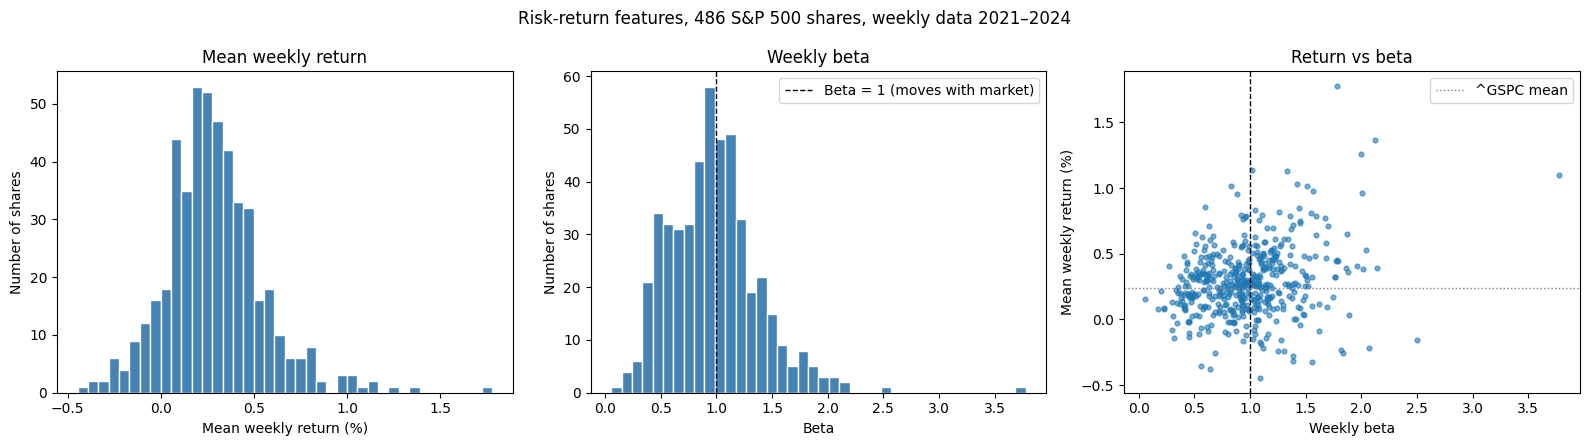

In [68]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(rr_features["mean_weekly_return"] * 100, bins=40, color="steelblue", edgecolor="white")
axes[0].set(title="Mean weekly return", xlabel="Mean weekly return (%)", ylabel="Number of shares")

axes[1].hist(rr_features["weekly_beta"], bins=40, color="steelblue", edgecolor="white")
axes[1].axvline(1, color="black", ls="--", lw=1, label="Beta = 1 (moves with market)")
axes[1].set(title="Weekly beta", xlabel="Beta", ylabel="Number of shares")
axes[1].legend()

axes[2].scatter(rr_features["weekly_beta"], rr_features["mean_weekly_return"] * 100, s=12, alpha=0.6)
axes[2].axvline(1, color="black", ls="--", lw=1)
axes[2].axhline(market_weekly.mean() * 100, color="grey", ls=":", lw=1, label="^GSPC mean")
axes[2].set(title="Return vs beta", xlabel="Weekly beta", ylabel="Mean weekly return (%)")
axes[2].legend()

plt.suptitle(f"Risk-return features, {len(rr_features)} S&P 500 shares, weekly data 2021–2024")
plt.tight_layout()
plt.savefig("fig_1_3_risk_return.png", dpi=150, bbox_inches="tight")
plt.show()

## Task 1.4 Adapted RFM Calculations

#### Observation date = final common completed trading date. A high-volume day has volume > 2 × the mean of the preceding 20 sessions (the tested day is excluded via .shift(1)), calculated separately for every share and day. R = calendar days from the latest event to the observation date (no event → missing, not zero). F = number of event days in the latest 60 sessions. M = Σ Close × Volume over the latest 60 sessions, in USD. yfinance Close and Volume are both split-adjusted, so their product is consistent across splits. M approximates traded value; it is not market capitalisation.

In [69]:
BASELINE, WINDOW, MULT = 20, 60, 2

base = prices_valid.drop_duplicates(["Ticker", "Date"])
vol_daily = base.pivot(index="Date", columns="Ticker", values="Volume").reindex(calendar).drop(columns=BENCHMARK)
close_px  = base.pivot(index="Date", columns="Ticker", values="Close").reindex(calendar)[vol_daily.columns]

# Final COMMON completed trading date across all valid shares
last_dates = base[base["Ticker"] != BENCHMARK].dropna(subset=["Close", "Volume"]).groupby("Ticker")["Date"].max()
OBS_DATE = last_dates.min()
print("Observation date:", OBS_DATE.date())
print("All shares end on this date:", (last_dates == OBS_DATE).all())

Observation date: 2024-12-31
All shares end on this date: True


In [70]:
baseline  = vol_daily.rolling(BASELINE, min_periods=BASELINE).mean().shift(1)   # preceding 20 sessions only
threshold = MULT * baseline
events    = ((vol_daily > threshold) & threshold.notna()).loc[:OBS_DATE]

print(f"Sessions without a full 20-day baseline (start of history): {int(baseline.iloc[:, 0].isna().sum())}")
print(f"Total high-volume events across all shares: {int(events.values.sum()):,}")

# No-look-ahead check: rebuild one threshold by hand from the 20 PRIOR sessions
t, d = "AAPL", calendar[100]
pos = calendar.get_loc(d)
manual = MULT * vol_daily[t].iloc[pos - BASELINE:pos].mean()
print(f"{t} on {d.date()}: manual threshold {manual:,.0f} | code {threshold.loc[d, t]:,.0f}")

Sessions without a full 20-day baseline (start of history): 20
Total high-volume events across all shares: 18,280
AAPL on 2021-05-27: manual threshold 180,693,870 | code 180,693,870


In [71]:
window_idx = calendar[calendar <= OBS_DATE][-WINDOW:]
assert len(window_idx) == WINDOW
assert baseline.loc[window_idx].notna().all().all(), "Insufficient history for the 20-session baseline"
print(f"60-session window: {window_idx[0].date()} to {window_idx[-1].date()}")

last_event = events.apply(lambda c: c[c].index.max())          # NaT if a share never had an event
rfm_features = pd.DataFrame({
    "last_event_date": last_event,
    "Recency_days":    (OBS_DATE - last_event).dt.days,         # calendar days, incl. weekends/holidays
    "Frequency_60":    events.loc[window_idx].sum().astype(int),
    "Monetary_usd":    (close_px.loc[window_idx] * vol_daily.loc[window_idx]).sum(),
})

no_event = rfm_features["Recency_days"].isna()
print(f"Event on the observation date (R = 0): {(rfm_features['Recency_days'] == 0).sum()}")
print(f"No qualifying event (R missing, excluded from RFM clustering): {no_event.sum()}")
if no_event.any():
    display(rfm_features[no_event])

# Combined feature table: one row per share; common set = shares with all 5 features
feature_table = rr_features.join(rfm_features)
FEATURES = ["mean_weekly_return", "weekly_beta", "Recency_days", "Frequency_60", "Monetary_usd"]
common = feature_table.dropna(subset=FEATURES)
print(f"Common valid share set for all clustering: {len(common)}")

feature_table.to_csv("feature_table.csv")
rfm_features[["Recency_days", "Frequency_60", "Monetary_usd"]].describe().round(1)

60-session window: 2024-10-07 to 2024-12-31
Event on the observation date (R = 0): 0
No qualifying event (R missing, excluded from RFM clustering): 0
Common valid share set for all clustering: 486


,Recency_days,Frequency_60,Monetary_usd
count,486.0,486.0,4.860000e+02
mean,20.4,3.0,3.940419e+10
std,21.3,1.3,1.291388e+11
min,4.0,0.0,1.297483e+09
25%,11.0,2.0,1.019517e+10
50%,11.0,3.0,1.668382e+10
75%,14.8,4.0,3.227689e+10
max,222.0,8.0,1.847697e+12


In [72]:
t = "AAPL" if rfm_features.loc["AAPL", "Frequency_60"] > 0 else \
    rfm_features[rfm_features["Frequency_60"].between(2, 5)].index[0]

ex = pd.DataFrame({"Close": close_px[t], "Volume": vol_daily[t], "Baseline_20d": baseline[t],
                   "Threshold_2x": threshold[t], "High_volume": events[t]}).loc[window_idx]
le = rfm_features.loc[t, "last_event_date"]

print(f"=== Worked RFM example: {t} | observation date {OBS_DATE.date()} ===\n")
print(f"Latest event {le.date()}: volume {vol_daily.loc[le, t]:,.0f} > 2 × {baseline.loc[le, t]:,.0f} "
      f"= {threshold.loc[le, t]:,.0f}  ✓")
print(f"R = {OBS_DATE.date()} − {le.date()} = {int(rfm_features.loc[t, 'Recency_days'])} calendar days")
print(f"F = {int(ex['High_volume'].sum())} qualifying days in the 60 sessions "
      f"({window_idx[0].date()} to {window_idx[-1].date()})")
print(f"M = Σ(Close × Volume) over 60 sessions = ${ex.eval('Close * Volume').sum():,.0f} "
      f"(≈ ${ex.eval('Close * Volume').sum() / 1e9:,.1f} bn)\n")
print("Qualifying days inside the window:")
display(ex[ex["High_volume"]].round(2))

=== Worked RFM example: AAPL | observation date 2024-12-31 ===

Latest event 2024-12-20: volume 147,495,300 > 2 × 45,004,605 = 90,009,210  ✓
R = 2024-12-31 − 2024-12-20 = 11 calendar days
F = 2 qualifying days in the 60 sessions (2024-10-07 to 2024-12-31)
M = Σ(Close × Volume) over 60 sessions = $623,303,377,707 (≈ $623.3 bn)

Qualifying days inside the window:


,Close,Volume,Baseline_20d,Threshold_2x,High_volume
Date,,,,,
2024-11-25,232.87,90152800.0,43820740.0,87641480.0,True
2024-12-20,254.49,147495300.0,45004605.0,90009210.0,True


In [73]:
# Boundary-case consistency between R and F
f0 = rfm_features[rfm_features["Frequency_60"] == 0]
print(f"Shares with F = 0: {len(f0)} | all have last event before the window: "
      f"{(f0['last_event_date'] < window_idx[0]).all()}")
print("All F > 0 shares have their last event inside the window:",
      (rfm_features.loc[rfm_features["Frequency_60"] > 0, "last_event_date"] >= window_idx[0]).all())

Shares with F = 0: 10 | all have last event before the window: True
All F > 0 shares have their last event inside the window: True


## Task 1.5 – Metric interpretation and supporting evidence

#### Feature summaries in original units, the share inclusion flow, a consolidated validation evidence table and the RFM distributions. The worked example is in Cell 20 (AAPL).

In [74]:
pd.set_option("display.max_colwidth", None)
# Metric definitions (reference table for the report)
definitions = pd.DataFrame([
    ("Mean weekly return", "Arithmetic mean of Friday-to-Friday Adj Close returns", "% per week", "207 weeks, 2021-01-15 to 2024-12-27"),
    ("Weekly beta",        "cov(share, ^GSPC) / var(^GSPC), weekly returns",        "ratio",      "207 weeks"),
    ("Recency (R)",        "Calendar days from latest high-volume day to observation date", "days", "Full valid history"),
    ("Frequency (F)",      "Count of high-volume days (> 2x prior 20-session mean)", "days",      "Last 60 sessions"),
    ("Monetary (M)",       "Sum of Close x Volume (approximate traded value)",       "USD",       "Last 60 sessions"),
], columns=["Metric", "Definition", "Units", "Window"])
display(definitions)

# Feature summary in ORIGINAL units, common share set
summary = common[FEATURES].copy()
summary["mean_weekly_return"] *= 100
summary["Monetary_usd"] /= 1e9
summary.columns = ["Mean weekly return (%)", "Weekly beta", "Recency (days)",
                   "Frequency (days in 60)", "Monetary (USD bn)"]

stats_tbl = summary.describe().T
stats_tbl["skew"] = summary.skew()
stats_tbl = stats_tbl[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "skew"]].round(3)
stats_tbl.to_csv("feature_summary.csv")
display(stats_tbl)

# Extremes per feature (useful for interpretation and outlier discussion in 2.1)
for col in summary.columns:
    print(f"{col:24s} highest: {', '.join(summary[col].nlargest(3).index):20s} "
          f"lowest: {', '.join(summary[col].nsmallest(3).index)}")

,Metric,Definition,Units,Window
0,Mean weekly return,Arithmetic mean of Friday-to-Friday Adj Close returns,% per week,"207 weeks, 2021-01-15 to 2024-12-27"
1,Weekly beta,"cov(share, ^GSPC) / var(^GSPC), weekly returns",ratio,207 weeks
2,Recency (R),Calendar days from latest high-volume day to observation date,days,Full valid history
3,Frequency (F),Count of high-volume days (> 2x prior 20-session mean),days,Last 60 sessions
4,Monetary (M),Sum of Close x Volume (approximate traded value),USD,Last 60 sessions


,count,mean,std,min,25%,50%,75%,max,skew
Mean weekly return (%),486.0,0.286,0.265,-0.447,0.118,0.262,0.421,1.777,0.868
Weekly beta,486.0,0.974,0.407,0.055,0.667,0.951,1.180,3.779,1.104
Recency (days),486.0,20.407,21.342,4.000,11.000,11.000,14.750,222.000,3.646
Frequency (days in 60),486.0,2.990,1.331,0.000,2.000,3.000,4.000,8.000,0.425
Monetary (USD bn),486.0,39.404,129.139,1.297,10.195,16.684,32.277,1847.697,11.684


Mean weekly return (%)   highest: SMCI, NVDA, VRT      lowest: EL, BAX, DG
Weekly beta              highest: CVNA, XYZ, COHR      lowest: GIS, SJM, MRK
Recency (days)           highest: NVDA, WEC, CB        lowest: AJG, NRG, SRE
Frequency (days in 60)   highest: CI, HSY, FOXA        lowest: AZO, CB, COR
Monetary (USD bn)        highest: TSLA, NVDA, AAPL     lowest: NWS, ECHO, FOX


In [75]:
# Share inclusion flow (inclusion/exclusion log summary)
flow = pd.DataFrame([
    ("Securities on Wikipedia constituent list",       len(sp500)),
    ("Price data returned by yfinance",                 int((checks["valid_days"] > 0).sum())),
    ("Passed validation rules (1.2)",                   len(valid_tickers)),
    ("Complete risk-return features (1.3)",             int(rr_features[["mean_weekly_return", "weekly_beta"]].notna().all(axis=1).sum())),
    ("Complete RFM features (1.4)",                     int(rfm_features[["Recency_days", "Frequency_60", "Monetary_usd"]].notna().all(axis=1).sum())),
    ("Common valid share set used for all clustering",  len(common)),
], columns=["Stage", "Shares"])
flow.to_csv("inclusion_flow.csv", index=False)
display(flow)

# Consolidated validation evidence (recomputed here so the table is self-contained)
X = market_weekly.values
slopes = np.polyfit(X, share_weekly[rr_features.index].values, 1)[0]
beta_max_diff = np.abs(slopes - rr_features["weekly_beta"].values).max()

d_chk = calendar[100]
pos = calendar.get_loc(d_chk)
manual_thr = MULT * vol_daily["AAPL"].iloc[pos - BASELINE:pos].mean()

f0 = rfm_features[rfm_features["Frequency_60"] == 0]

evidence = pd.DataFrame([
    ("Duplicate ticker-date rows",                          int(dups)),
    ("Share and benchmark week labels identical",          bool(share_weekly.index.equals(market_weekly.index))),
    ("Aligned weekly observations per share",              int(rr_features["n_weeks"].iloc[0])),
    ("Missing weekly returns",                             int(share_weekly.isna().sum().sum())),
    ("Max |cov/var beta - OLS slope| (all shares)",        f"{beta_max_diff:.2e}"),
    ("Event threshold uses only prior 20 sessions",        bool(np.isclose(manual_thr, threshold.loc[d_chk, "AAPL"]))),
    ("Full 20-session baseline across 60-session window",  bool(baseline.loc[window_idx].notna().all().all())),
    ("Observation date",                                   str(OBS_DATE.date())),
    ("Shares with R = 0 (event on observation date)",      int((rfm_features["Recency_days"] == 0).sum())),
    ("Shares with no qualifying event (R missing)",        int(rfm_features["Recency_days"].isna().sum())),
    ("F = 0 shares all have last event before window",     bool((f0["last_event_date"] < window_idx[0]).all())),
], columns=["Check", "Result"])
evidence.to_csv("validation_evidence.csv", index=False)
display(evidence)

,Stage,Shares
0,Securities on Wikipedia constituent list,503
1,Price data returned by yfinance,498
2,Passed validation rules (1.2),486
3,Complete risk-return features (1.3),486
4,Complete RFM features (1.4),486
5,Common valid share set used for all clustering,486


,Check,Result
0,Duplicate ticker-date rows,0
1,Share and benchmark week labels identical,True
2,Aligned weekly observations per share,207
3,Missing weekly returns,0
4,Max |cov/var beta - OLS slope| (all shares),2.22e-15
5,Event threshold uses only prior 20 sessions,True
6,Full 20-session baseline across 60-session window,True
7,Observation date,2024-12-31
8,Shares with R = 0 (event on observation date),0
9,Shares with no qualifying event (R missing),0


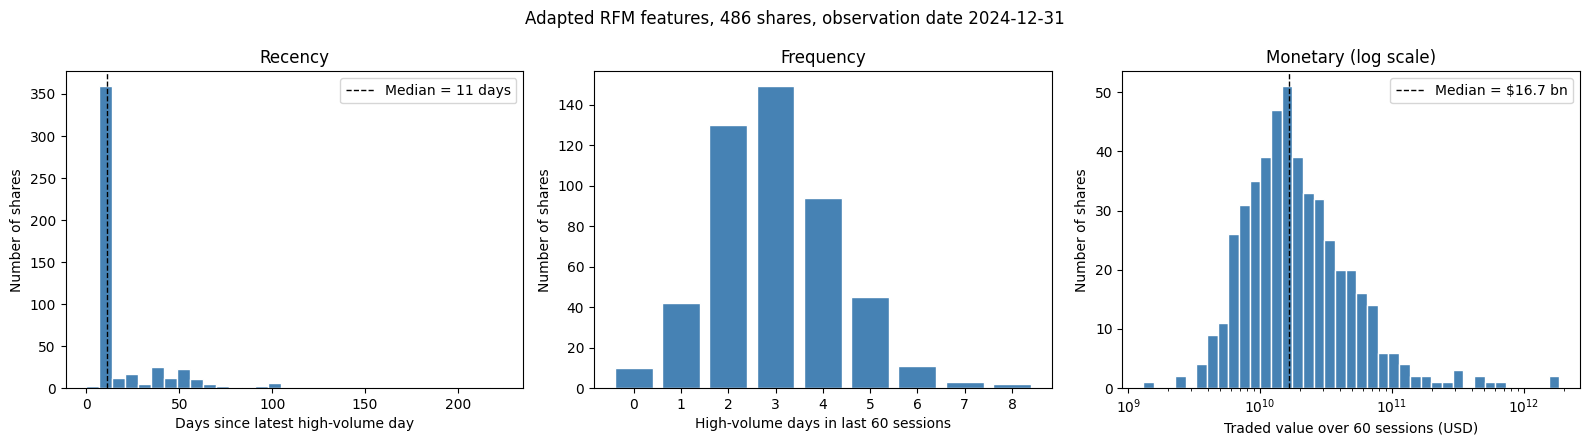

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Recency: weekly bins; mark the median
r = common["Recency_days"]
axes[0].hist(r, bins=range(0, int(r.max()) + 8, 7), color="steelblue", edgecolor="white")
axes[0].axvline(r.median(), color="black", ls="--", lw=1, label=f"Median = {r.median():.0f} days")
axes[0].set(title="Recency", xlabel="Days since latest high-volume day", ylabel="Number of shares")
axes[0].legend()

# Frequency: discrete counts, so a bar chart rather than a histogram
f_counts = common["Frequency_60"].value_counts().sort_index()
axes[1].bar(f_counts.index, f_counts.values, color="steelblue", edgecolor="white")
axes[1].set(title="Frequency", xlabel="High-volume days in last 60 sessions", ylabel="Number of shares")
axes[1].set_xticks(f_counts.index)

# Monetary: log scale, because values span ~3 orders of magnitude
m = common["Monetary_usd"]
axes[2].hist(m, bins=np.logspace(np.log10(m.min()), np.log10(m.max()), 40), color="steelblue", edgecolor="white")
axes[2].set_xscale("log")
axes[2].axvline(m.median(), color="black", ls="--", lw=1, label=f"Median = ${m.median()/1e9:.1f} bn")
axes[2].set(title="Monetary (log scale)", xlabel="Traded value over 60 sessions (USD)", ylabel="Number of shares")
axes[2].legend()

plt.suptitle(f"Adapted RFM features, {len(common)} shares, observation date {OBS_DATE.date()}")
plt.tight_layout()
plt.savefig("fig_1_5_rfm_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [77]:
print((common["Recency_days"] == 11).sum(), "shares with R = 11")

353 shares with R = 11


# Task 2 – Stock Segmentation and Sensitivity Analysis

## Task 2.1 – Feature preparation

#### Two separate matrices are built from the same 486-share common set: risk-return (mean weekly return, weekly beta) and trading activity (R, F, M). Monetary is log1p-transformed, as in the module clustering tutorial, then each matrix is standardised separately. Skew and outliers are inspected before and after transformation.

In [78]:
from sklearn.preprocessing import StandardScaler

RR_COLS  = ["mean_weekly_return", "weekly_beta"]
RFM_COLS = ["Recency_days", "Frequency_60", "Monetary_usd"]

X_rr_raw  = common[RR_COLS].copy()
X_rfm_raw = common[RFM_COLS].copy()

assert X_rr_raw.index.equals(X_rfm_raw.index), "Matrices must use the same shares"
assert X_rr_raw.notna().all().all() and X_rfm_raw.notna().all().all()
print(f"Common share set: {len(common)} shares | "
      f"risk-return matrix {X_rr_raw.shape} | RFM matrix {X_rfm_raw.shape}")

Common share set: 486 shares | risk-return matrix (486, 2) | RFM matrix (486, 3)


In [79]:
def diagnostics(df):
    """Skew, IQR outliers and standardised extremes for each column."""
    z = (df - df.mean()) / df.std(ddof=0)
    q1, q3 = df.quantile(0.25), df.quantile(0.75)
    iqr = q3 - q1
    return pd.DataFrame({
        "skew":         df.skew(),
        "IQR outliers": ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum(),
        "|z| > 3":      (z.abs() > 3).sum(),
        "max |z|":      z.abs().max(),
    }).round(2)

print("Raw features:")
display(diagnostics(common[RR_COLS + RFM_COLS]))

# Candidate transformations for the two most skewed variables
candidates = pd.DataFrame({
    "log1p(Monetary)": np.log1p(common["Monetary_usd"]),
    "log1p(Recency)":  np.log1p(common["Recency_days"]),
})
print("After log1p:")
display(diagnostics(candidates))

print(f"Share of firms at the modal Recency (11 days): {(common['Recency_days'] == 11).mean():.1%} "
      "- a log transform cannot remove this concentration")

Raw features:


,skew,IQR outliers,|z| > 3,max |z|
mean_weekly_return,0.87,15,6,5.63
weekly_beta,1.10,10,2,6.89
Recency_days,3.65,115,11,9.46
Frequency_60,0.42,2,5,3.77
Monetary_usd,11.68,45,5,14.02


After log1p:


,skew,IQR outliers,|z| > 3,max |z|
log1p(Monetary),1.08,13,7,4.85
log1p(Recency),1.58,113,2,4.22


Share of firms at the modal Recency (11 days): 72.6% - a log transform cannot remove this concentration


In [80]:
# Risk-return: no transformation (moderate skew, outliers are genuine shares)
scaler_rr = StandardScaler()
Z_rr = pd.DataFrame(scaler_rr.fit_transform(X_rr_raw), index=X_rr_raw.index, columns=RR_COLS)

# RFM: log1p on Monetary only (as required), R and F left in original form
X_rfm = X_rfm_raw.copy()
X_rfm["Monetary_usd"] = np.log1p(X_rfm["Monetary_usd"])
X_rfm = X_rfm.rename(columns={"Monetary_usd": "log1p_Monetary"})

scaler_rfm = StandardScaler()
Z_rfm = pd.DataFrame(scaler_rfm.fit_transform(X_rfm), index=X_rfm.index, columns=X_rfm.columns)

for name, Z in [("Risk-return", Z_rr), ("RFM", Z_rfm)]:
    print(f"{name}: means {Z.mean().round(6).tolist()} | std (population) {Z.std(ddof=0).round(6).tolist()}")

# How the log transform changes distances: compare standardised Monetary before and after
z_raw_m = (common["Monetary_usd"] - common["Monetary_usd"].mean()) / common["Monetary_usd"].std(ddof=0)
z_log_m = Z_rfm["log1p_Monetary"]
print(f"\nMax |z| of Monetary: raw = {z_raw_m.abs().max():.1f} SD | after log1p = {z_log_m.abs().max():.1f} SD")
print("Top 3 by traded value, z-scores raw vs log1p:")
display(pd.DataFrame({"raw z": z_raw_m, "log1p z": z_log_m}).loc[
    common["Monetary_usd"].nlargest(3).index].round(2))

# Shares that remain extreme after preparation (|z| > 3) - retained, but noted
extreme = pd.concat([Z_rr, Z_rfm], axis=1)
extreme = extreme[(extreme.abs() > 3).any(axis=1)].round(2)
print(f"\nShares with |z| > 3 on any prepared feature: {len(extreme)}")
display(extreme)

Z_rr.to_csv("matrix_risk_return_scaled.csv")
Z_rfm.to_csv("matrix_rfm_scaled.csv")

Risk-return: means [-0.0, 0.0] | std (population) [1.0, 1.0]
RFM: means [-0.0, -0.0, -0.0] | std (population) [1.0, 1.0, 1.0]

Max |z| of Monetary: raw = 14.0 SD | after log1p = 4.8 SD
Top 3 by traded value, z-scores raw vs log1p:


,raw z,log1p z
Ticker,,
TSLA,14.02,4.85
NVDA,13.84,4.83
AAPL,4.53,3.69



Shares with |z| > 3 on any prepared feature: 28


,mean_weekly_return,weekly_beta,Recency_days,Frequency_60,log1p_Monetary
Ticker,,,,,
AAPL,0.40,0.49,-0.44,-0.74,3.69
AMZN,-0.07,1.01,-0.44,1.51,3.39
APD,-0.63,-0.65,3.03,-1.50,0.34
AVGO,2.75,1.33,-0.44,2.26,3.03
AZO,0.91,-0.53,3.64,-2.25,0.27
CB,0.25,-0.98,3.83,-2.25,0.29
CI,-0.31,-1.38,-0.35,3.77,0.72
COR,0.57,-1.05,3.83,-2.25,-0.10
CVNA,3.06,6.89,0.73,0.01,0.73


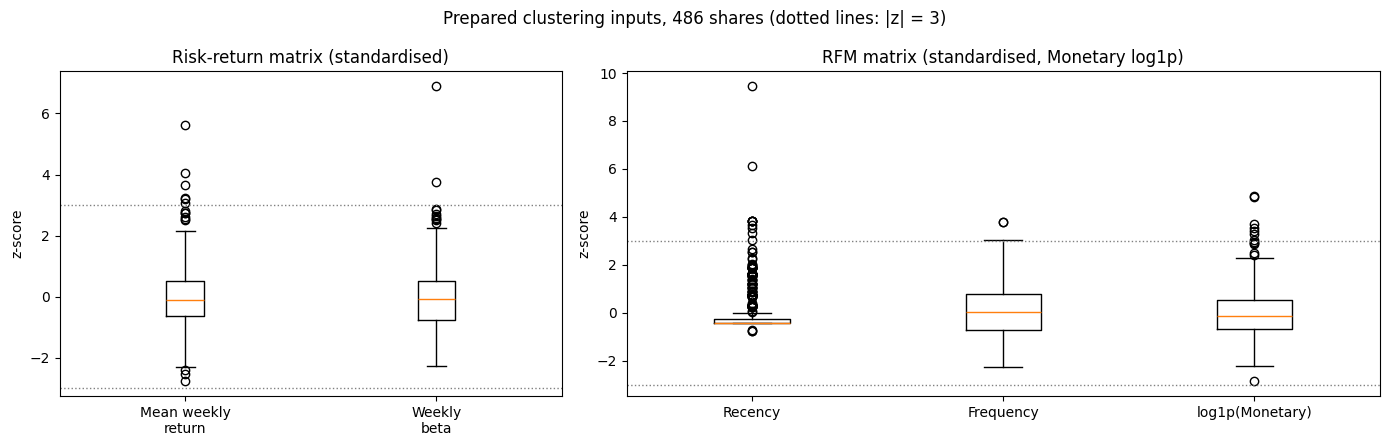

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 3]})

axes[0].boxplot(Z_rr.values, tick_labels=["Mean weekly\nreturn", "Weekly\nbeta"])
axes[0].set(title="Risk-return matrix (standardised)", ylabel="z-score")

axes[1].boxplot(Z_rfm.values, tick_labels=["Recency", "Frequency", "log1p(Monetary)"])
axes[1].set(title="RFM matrix (standardised, Monetary log1p)", ylabel="z-score")

for ax in axes:
    ax.axhline(3, color="grey", ls=":", lw=1)
    ax.axhline(-3, color="grey", ls=":", lw=1)

plt.suptitle(f"Prepared clustering inputs, {len(common)} shares (dotted lines: |z| = 3)")
plt.tight_layout()
plt.savefig("fig_2_1_prepared_features.png", dpi=150, bbox_inches="tight")
plt.show()

## Task 2.2: Agglomerative (Ward) clustering

#### Ward linkage with Euclidean distance on each standardised matrix, as in the module clustering tutorial. Cluster counts 2–8 are compared using silhouette scores, cluster sizes, dendrogram merge gaps and profiles in original units. The dendrogram colour threshold is not used to choose k.

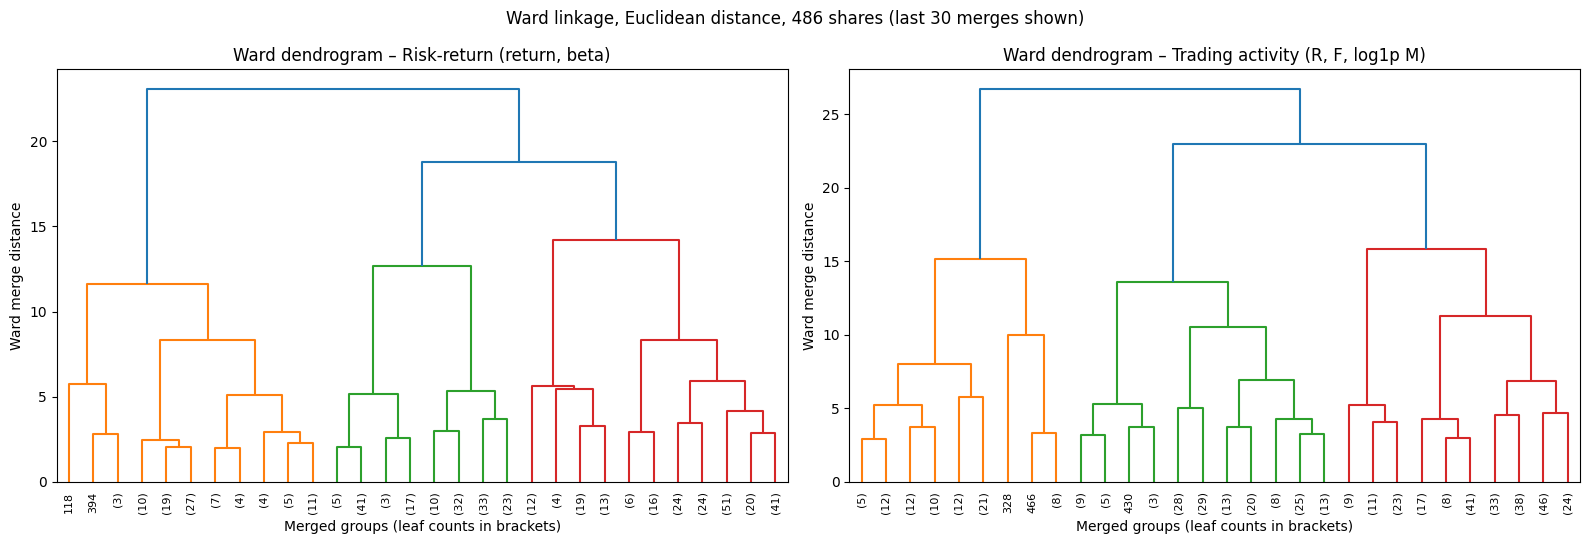

In [82]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score

L_rr  = linkage(Z_rr.values,  method="ward", metric="euclidean")
L_rfm = linkage(Z_rfm.values, method="ward", metric="euclidean")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, L, title in [(axes[0], L_rr, "Risk-return (return, beta)"),
                     (axes[1], L_rfm, "Trading activity (R, F, log1p M)")]:
    dendrogram(L, ax=ax, truncate_mode="lastp", p=30, show_leaf_counts=True,
               leaf_rotation=90, leaf_font_size=8)
    ax.set(title=f"Ward dendrogram – {title}", xlabel="Merged groups (leaf counts in brackets)",
           ylabel="Ward merge distance")
plt.suptitle(f"Ward linkage, Euclidean distance, {len(common)} shares (last 30 merges shown)")
plt.tight_layout()
plt.savefig("fig_2_2_dendrograms.png", dpi=150, bbox_inches="tight")
plt.show()

Cophenetic correlation – Risk-return: 0.479
Cophenetic correlation – RFM: 0.508

Ward – risk-return


,silhouette (↑),Calinski-Harabasz (↑),Davies-Bouldin (↓),merge gap (↑),smallest cluster,sizes
k,,,,,,
2,0.339,182.536,1.059,4.271,92,"[394, 92]"
3,0.274,202.207,1.129,4.592,92,"[230, 164, 92]"
4,0.282,204.153,1.150,1.541,48,"[182, 164, 92, 48]"
5,0.304,215.797,0.938,1.068,48,"[182, 98, 92, 66, 48]"
6,0.320,236.638,0.858,3.260,5,"[182, 98, 87, 66, 48, 5]"
7,0.324,235.952,0.839,0.033,5,"[160, 98, 87, 66, 48, 22, 5]"
8,0.321,245.960,0.851,2.379,5,"[160, 98, 66, 56, 48, 31, 22, 5]"



Ward – RFM


,silhouette (↑),Calinski-Harabasz (↑),Davies-Bouldin (↓),merge gap (↑),smallest cluster,sizes
k,,,,,,
2,0.368,156.703,1.175,3.720,82,"[404, 82]"
3,0.304,179.058,1.181,7.142,82,"[250, 154, 82]"
4,0.289,168.463,1.022,0.691,43,"[207, 154, 82, 43]"
5,0.305,173.456,0.977,1.572,10,"[207, 154, 72, 43, 10]"
6,0.314,181.314,0.955,2.287,10,"[207, 136, 72, 43, 18, 10]"
7,0.292,184.129,0.929,0.756,10,"[141, 136, 72, 66, 43, 18, 10]"
8,0.302,190.012,0.923,0.568,10,"[141, 79, 72, 66, 57, 43, 18, 10]"


SciPy vs scikit-learn agreement (Risk-return, k=4): ARI = 1.000
SciPy vs scikit-learn agreement (RFM, k=4): ARI = 1.000


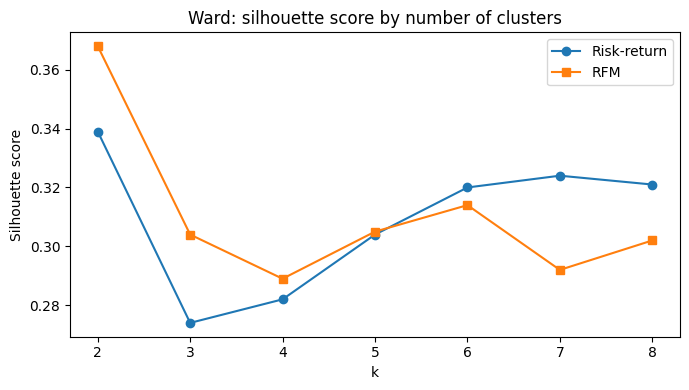

In [83]:
from scipy.cluster.hierarchy import cophenet
from scipy.spatial.distance import pdist
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from sklearn.cluster import AgglomerativeClustering

# 1. Dendrogram quality: how well tree distances preserve the original pairwise distances
for name, Z, L in [("Risk-return", Z_rr, L_rr), ("RFM", Z_rfm, L_rfm)]:
    c, _ = cophenet(L, pdist(Z.values))
    print(f"Cophenetic correlation – {name}: {c:.3f}")

def evaluate_ward(Z, L, name):
    """Silhouette, Calinski-Harabasz, Davies-Bouldin, sizes and merge gap for k = 2..8."""
    heights = L[:, 2][::-1]                      # heights[0] = final merge (2 -> 1)
    rows = []
    for k in range(2, 9):
        labels = fcluster(L, t=k, criterion="maxclust")
        sizes = np.bincount(labels)[1:]
        rows.append({"k": k,
                     "silhouette (↑)":        silhouette_score(Z, labels),
                     "Calinski-Harabasz (↑)": calinski_harabasz_score(Z, labels),
                     "Davies-Bouldin (↓)":    davies_bouldin_score(Z, labels),
                     "merge gap (↑)":         heights[k - 2] - heights[k - 1],
                     "smallest cluster":      sizes.min(),
                     "sizes":                 sorted(sizes.tolist(), reverse=True)})
    out = pd.DataFrame(rows).set_index("k").round(3)
    print(f"\n{name}")
    display(out)
    return out

ward_rr_eval  = evaluate_ward(Z_rr,  L_rr,  "Ward – risk-return")
ward_rfm_eval = evaluate_ward(Z_rfm, L_rfm, "Ward – RFM")

# 2. Reproducibility: SciPy and scikit-learn Ward should give identical memberships
for name, Z, L in [("Risk-return", Z_rr, L_rr), ("RFM", Z_rfm, L_rfm)]:
    sk = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(Z)
    sp = fcluster(L, 4, "maxclust")
    print(f"SciPy vs scikit-learn agreement ({name}, k=4): ARI = {adjusted_rand_score(sk, sp):.3f}")

# 3. Silhouette plot for both matrices
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ward_rr_eval.index,  ward_rr_eval["silhouette (↑)"],  "o-", label="Risk-return")
ax.plot(ward_rfm_eval.index, ward_rfm_eval["silhouette (↑)"], "s-", label="RFM")
ax.set(title="Ward: silhouette score by number of clusters", xlabel="k", ylabel="Silhouette score")
ax.legend()
plt.tight_layout()
plt.savefig("fig_2_2_ward_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

In [84]:
# Original-unit view: return in %, Monetary in USD bn
orig = common[RR_COLS + RFM_COLS].copy()
orig["mean_weekly_return"] *= 100
orig["Monetary_usd"] /= 1e9
orig.columns = ["Return %/wk", "Beta", "R (days)", "F (days)", "M ($bn)"]

def profile(labels, cols):
    lab = pd.Series(labels, index=common.index, name="Cluster")
    p = orig[cols].groupby(lab).median().round(3)        # medians: robust to outliers
    p.insert(0, "n", lab.value_counts().sort_index())
    return p

for k in [2, 3, 4, 5]:
    print(f"--- Risk-return, Ward, k = {k} (medians) ---")
    display(profile(fcluster(L_rr, k, "maxclust"), ["Return %/wk", "Beta"]))
for k in [2, 3, 4, 5]:
    print(f"--- RFM, Ward, k = {k} (medians) ---")
    display(profile(fcluster(L_rfm, k, "maxclust"), ["R (days)", "F (days)", "M ($bn)"]))

--- Risk-return, Ward, k = 2 (medians) ---


,n,Return %/wk,Beta
Cluster,,,
1,92,0.550,1.218
2,394,0.209,0.882


--- Risk-return, Ward, k = 3 (medians) ---


,n,Return %/wk,Beta
Cluster,,,
1,92,0.550,1.218
2,164,0.327,0.578
3,230,0.171,1.038


--- Risk-return, Ward, k = 4 (medians) ---


,n,Return %/wk,Beta
Cluster,,,
1,92,0.550,1.218
2,164,0.327,0.578
3,48,0.252,1.514
4,182,0.166,0.964


... (6 outputs left out)

--- RFM, Ward, k = 4 (medians) ---


,n,R (days),F (days),M ($bn)
Cluster,,,,
1,82,54.5,2.0,17.849
2,154,11.0,3.0,39.695
3,43,11.0,5.0,14.430
4,207,11.0,3.0,10.785


--- RFM, Ward, k = 5 (medians) ---


,n,R (days),F (days),M ($bn)
Cluster,,,,
1,72,53.0,2.0,17.682
2,10,102.0,0.0,23.786
3,154,11.0,3.0,39.695
4,43,11.0,5.0,14.430
5,207,11.0,3.0,10.785


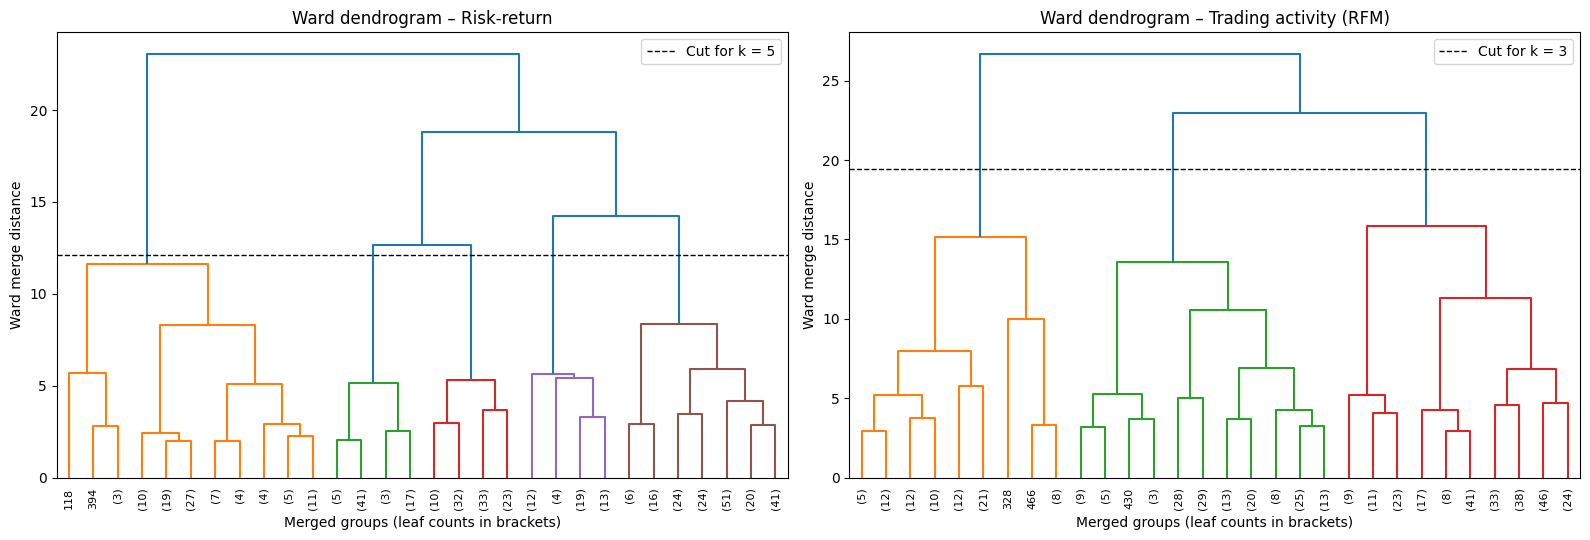

Risk-return: mean silhouette 0.304 | negative-silhouette shares: 38 (7.8%)


,count,mean,min
ward_rr,,,
1,92,0.164,-0.204
2,66,0.465,0.002
3,98,0.382,-0.084
4,48,0.306,0.069
5,182,0.274,-0.345


RFM: mean silhouette 0.304 | negative-silhouette shares: 33 (6.8%)


,count,mean,min
ward_rfm,,,
1,82,0.184,-0.483
2,154,0.247,-0.159
3,250,0.378,0.032


Risk-return Ward profiles:


,n,Return %/wk,Beta
Cluster,,,
1,92,0.550,1.218
2,66,0.113,0.448
3,98,0.392,0.666
4,48,0.252,1.514
5,182,0.166,0.964


RFM Ward profiles:


,n,R (days),F (days),M ($bn)
Cluster,,,,
1,82,54.5,2.0,17.849
2,154,11.0,3.0,39.695
3,250,11.0,3.0,11.178


Saved cluster_assignments.csv: (486, 4)


In [85]:
from sklearn.metrics import silhouette_samples

K_WARD_RR, K_WARD_RFM = 5, 3      # chosen from Cells 29-30: sizes, merge gaps, indices, profiles

ward_rr  = pd.Series(fcluster(L_rr,  K_WARD_RR,  "maxclust"), index=common.index, name="ward_rr")
ward_rfm = pd.Series(fcluster(L_rfm, K_WARD_RFM, "maxclust"), index=common.index, name="ward_rfm")

def cut_height(L, k):
    """Height midway between the merges that produce k and k-1 clusters."""
    h = L[:, 2][::-1]
    return (h[k - 2] + h[k - 1]) / 2

# Dendrograms coloured by the CHOSEN k, with the cut line drawn
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, L, k, title in [(axes[0], L_rr,  K_WARD_RR,  "Risk-return"),
                        (axes[1], L_rfm, K_WARD_RFM, "Trading activity (RFM)")]:
    cut = cut_height(L, k)
    dendrogram(L, ax=ax, truncate_mode="lastp", p=30, show_leaf_counts=True,
               leaf_rotation=90, leaf_font_size=8, color_threshold=cut)
    ax.axhline(cut, color="black", ls="--", lw=1, label=f"Cut for k = {k}")
    ax.set(title=f"Ward dendrogram – {title}", xlabel="Merged groups (leaf counts in brackets)",
           ylabel="Ward merge distance")
    ax.legend()
plt.tight_layout()
plt.savefig("fig_2_2_dendrograms_final.png", dpi=150, bbox_inches="tight")
plt.show()

# Per-share silhouettes: how many shares sit poorly in their cluster?
for name, Z, lab in [("Risk-return", Z_rr, ward_rr), ("RFM", Z_rfm, ward_rfm)]:
    s = pd.Series(silhouette_samples(Z, lab), index=common.index)
    print(f"{name}: mean silhouette {s.mean():.3f} | negative-silhouette shares: "
          f"{(s < 0).sum()} ({(s < 0).mean():.1%})")
    display(s.groupby(lab).agg(["count", "mean", "min"]).round(3))

# Final profiles in original units (medians)
print("Risk-return Ward profiles:")
display(profile(ward_rr, ["Return %/wk", "Beta"]))
print("RFM Ward profiles:")
display(profile(ward_rfm, ["R (days)", "F (days)", "M ($bn)"]))

# Cluster assignment table (K-means columns are added in 2.3)
cluster_assignments = pd.DataFrame({"ward_rr": ward_rr, "ward_rfm": ward_rfm}).join(
    common[["Security", "GICS Sector"]])
cluster_assignments.to_csv("cluster_assignments.csv")
print("Saved cluster_assignments.csv:", cluster_assignments.shape)

## Task 2.3: K-means clustering

#### K-means on the same standardised matrices, with a fixed random seed (42) and 50 initialisations per fit. k = 2–8 is compared using silhouette, inertia (elbow), Calinski-Harabasz, Davies-Bouldin and cluster sizes. Initialisation stability is tested by refitting with 20 different single-start seeds.


K-means – risk-return


,inertia (elbow),silhouette (↑),Calinski-Harabasz (↑),Davies-Bouldin (↓),smallest cluster,sizes
k,,,,,,
2,621.634,0.387,272.792,1.070,143,"[343, 143]"
3,461.179,0.329,267.496,1.010,119,"[202, 165, 119]"
4,371.571,0.326,259.633,0.936,41,"[160, 153, 132, 41]"
5,309.960,0.338,256.841,0.869,28,"[165, 124, 114, 55, 28]"
6,265.707,0.326,255.184,0.887,20,"[134, 115, 85, 76, 56, 20]"
7,227.239,0.329,261.649,0.852,5,"[126, 105, 84, 78, 47, 41, 5]"
8,194.249,0.354,273.407,0.839,5,"[135, 80, 78, 76, 43, 40, 29, 5]"



K-means – RFM


,inertia (elbow),silhouette (↑),Calinski-Harabasz (↑),Davies-Bouldin (↓),smallest cluster,sizes
k,,,,,,
2,1066.832,0.423,177.465,1.047,68,"[418, 68]"
3,796.614,0.325,200.504,1.139,64,"[270, 152, 64]"
4,609.832,0.341,223.459,0.937,61,"[212, 122, 91, 61]"
5,514.714,0.358,220.375,0.895,11,"[198, 122, 87, 68, 11]"
6,437.365,0.347,224.026,0.912,11,"[142, 120, 105, 68, 40, 11]"
7,386.260,0.349,221.510,0.780,1,"[142, 120, 104, 68, 40, 11, 1]"
8,341.994,0.342,222.832,0.789,1,"[152, 101, 88, 66, 48, 19, 11, 1]"


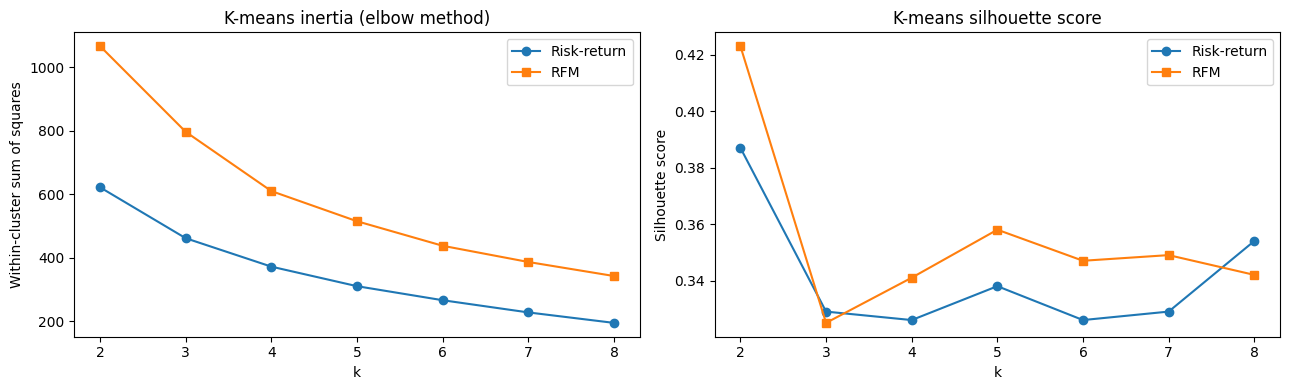

In [86]:
from sklearn.cluster import KMeans

SEED = 42

def evaluate_kmeans(Z, name):
    """Seeded K-means with multiple initialisations for k = 2..8."""
    rows = []
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
        sizes = np.bincount(km.labels_)
        rows.append({"k": k,
                     "inertia (elbow)":       km.inertia_,
                     "silhouette (↑)":        silhouette_score(Z, km.labels_),
                     "Calinski-Harabasz (↑)": calinski_harabasz_score(Z, km.labels_),
                     "Davies-Bouldin (↓)":    davies_bouldin_score(Z, km.labels_),
                     "smallest cluster":      sizes.min(),
                     "sizes":                 sorted(sizes.tolist(), reverse=True)})
    out = pd.DataFrame(rows).set_index("k").round(3)
    print(f"\n{name}")
    display(out)
    return out

km_rr_eval  = evaluate_kmeans(Z_rr,  "K-means – risk-return")
km_rfm_eval = evaluate_kmeans(Z_rfm, "K-means – RFM")

# Elbow and silhouette plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ev, label, marker in [(km_rr_eval, "Risk-return", "o-"), (km_rfm_eval, "RFM", "s-")]:
    axes[0].plot(ev.index, ev["inertia (elbow)"], marker, label=label)
    axes[1].plot(ev.index, ev["silhouette (↑)"], marker, label=label)
axes[0].set(title="K-means inertia (elbow method)", xlabel="k", ylabel="Within-cluster sum of squares")
axes[1].set(title="K-means silhouette score", xlabel="k", ylabel="Silhouette score")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig("fig_2_3_kmeans_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

In [87]:
def init_stability(Z, k, n_seeds=20):
    """Compare 20 single-start fits against the best 50-start solution."""
    best = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
    inertias, aris = [], []
    for s in range(n_seeds):
        km = KMeans(n_clusters=k, n_init=1, random_state=s).fit(Z)
        inertias.append(km.inertia_)
        aris.append(adjusted_rand_score(best.labels_, km.labels_))
    return {"k": k,
            "best inertia (50 starts)": round(best.inertia_, 2),
            "single-start inertia range": f"{min(inertias):.2f} – {max(inertias):.2f}",
            "mean ARI vs best": round(np.mean(aris), 3),
            "runs matching best (ARI > 0.99)": f"{sum(a > 0.99 for a in aris)}/{n_seeds}"}

for name, Z in [("Risk-return", Z_rr), ("RFM", Z_rfm)]:
    print(f"\nInitialisation stability – {name}")
    display(pd.DataFrame([init_stability(Z, k) for k in [3, 4, 5]]).set_index("k"))


Initialisation stability – Risk-return


,best inertia (50 starts),single-start inertia range,mean ARI vs best,runs matching best (ARI > 0.99)
k,,,,
3,461.18,461.18 – 461.37,0.995,19/20
4,371.57,371.58 – 393.68,0.766,0/20
5,309.96,310.30 – 331.70,0.547,0/20



Initialisation stability – RFM


,best inertia (50 starts),single-start inertia range,mean ARI vs best,runs matching best (ARI > 0.99)
k,,,,
3,796.61,796.61 – 915.33,0.723,5/20
4,609.83,609.83 – 728.52,0.776,13/20
5,514.71,514.71 – 561.96,0.779,5/20


In [88]:
for k in [3, 4, 5]:
    lab = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(Z_rr) + 1
    print(f"--- Risk-return, K-means, k = {k} (medians) ---")
    display(profile(lab, ["Return %/wk", "Beta"]))
for k in [2, 3, 4]:
    lab = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(Z_rfm) + 1
    print(f"--- RFM, K-means, k = {k} (medians) ---")
    display(profile(lab, ["R (days)", "F (days)", "M ($bn)"]))

--- Risk-return, K-means, k = 3 (medians) ---


,n,Return %/wk,Beta
Cluster,,,
1,119,0.528,1.221
2,202,0.259,0.622
3,165,0.118,1.081


--- Risk-return, K-means, k = 4 (medians) ---


,n,Return %/wk,Beta
Cluster,,,
1,160,0.432,0.982
2,41,0.687,1.677
3,132,0.113,1.142
4,153,0.186,0.575


--- Risk-return, K-means, k = 5 (medians) ---


,n,Return %/wk,Beta
Cluster,,,
1,165,0.415,0.999
2,114,0.072,0.978
3,28,0.823,1.482
4,124,0.210,0.519
5,55,0.253,1.501


... (2 outputs left out)

--- RFM, K-means, k = 3 (medians) ---


,n,R (days),F (days),M ($bn)
Cluster,,,,
1,270,11.0,3.0,11.371
2,64,55.0,2.0,21.147
3,152,11.0,3.0,41.602


--- RFM, K-means, k = 4 (medians) ---


,n,R (days),F (days),M ($bn)
Cluster,,,,
1,212,11.0,2.0,13.336
2,122,11.0,4.0,12.826
3,61,55.0,2.0,21.242
4,91,11.0,3.0,60.183


In [89]:
K_KM_RR, K_KM_RFM = 3, 4          # chosen from Cells 32-34: stability, indices, sizes, profiles

km_rr_model  = KMeans(n_clusters=K_KM_RR,  n_init=50, random_state=SEED).fit(Z_rr)
km_rfm_model = KMeans(n_clusters=K_KM_RFM, n_init=50, random_state=SEED).fit(Z_rfm)
km_rr  = pd.Series(km_rr_model.labels_ + 1,  index=common.index, name="kmeans_rr")
km_rfm = pd.Series(km_rfm_model.labels_ + 1, index=common.index, name="kmeans_rfm")

# Centroids converted back to original units (Monetary: expm1 reverses log1p)
cent_rr = pd.DataFrame(scaler_rr.inverse_transform(km_rr_model.cluster_centers_),
                       columns=["Return %/wk", "Beta"], index=range(1, K_KM_RR + 1))
cent_rr["Return %/wk"] *= 100
cent_rfm = pd.DataFrame(scaler_rfm.inverse_transform(km_rfm_model.cluster_centers_),
                        columns=["R (days)", "F (days)", "M ($bn)"], index=range(1, K_KM_RFM + 1))
cent_rfm["M ($bn)"] = np.expm1(cent_rfm["M ($bn)"]) / 1e9
print("K-means centroids in original units (risk-return):")
display(cent_rr.round(3))
print("K-means centroids in original units (RFM; M centre is on the log scale, so a geometric-type centre):")
display(cent_rfm.round(2))

# Per-share silhouettes
for name, Z, lab in [("Risk-return", Z_rr, km_rr), ("RFM", Z_rfm, km_rfm)]:
    s = pd.Series(silhouette_samples(Z, lab), index=common.index)
    print(f"{name}: mean silhouette {s.mean():.3f} | negative-silhouette shares: "
          f"{(s < 0).sum()} ({(s < 0).mean():.1%})")
    display(s.groupby(lab).agg(["count", "mean", "min"]).round(3))

# Median profiles (same method as Ward, for comparability)
print("Risk-return K-means profiles (medians):")
display(profile(km_rr, ["Return %/wk", "Beta"]))
print("RFM K-means profiles (medians):")
display(profile(km_rfm, ["R (days)", "F (days)", "M ($bn)"]))

# Add to the cluster assignment table: four baseline solutions
cluster_assignments = pd.DataFrame({"ward_rr": ward_rr, "kmeans_rr": km_rr,
                                    "ward_rfm": ward_rfm, "kmeans_rfm": km_rfm}).join(
    common[["Security", "GICS Sector"]])
cluster_assignments.to_csv("cluster_assignments.csv")
print("Saved cluster_assignments.csv with all four baseline solutions:", cluster_assignments.shape)

K-means centroids in original units (risk-return):


,Return %/wk,Beta
1,0.596,1.326
2,0.259,0.631
3,0.095,1.139


K-means centroids in original units (RFM; M centre is on the log scale, so a geometric-type centre):


,R (days),F (days),M ($bn)
1,13.26,2.37,12.98
2,13.94,4.55,12.87
3,66.02,1.67,22.52
4,15.14,3.23,75.03


Risk-return: mean silhouette 0.329 | negative-silhouette shares: 6 (1.2%)


,count,mean,min
kmeans_rr,,,
1,119,0.274,-0.059
2,202,0.384,0.015
3,165,0.301,-0.005


... (3 outputs left out)

,n,Return %/wk,Beta
Cluster,,,
1,119,0.528,1.221
2,202,0.259,0.622
3,165,0.118,1.081


RFM K-means profiles (medians):


,n,R (days),F (days),M ($bn)
Cluster,,,,
1,212,11.0,2.0,13.336
2,122,11.0,4.0,12.826
3,61,55.0,2.0,21.242
4,91,11.0,3.0,60.183


Saved cluster_assignments.csv with all four baseline solutions: (486, 6)


## Task 2.4 – Cluster profiles and algorithm comparison

#### Cluster numbers are arbitrary, so each cluster is given a descriptive name from its median profile. The risk-return matrix is already two-dimensional and is plotted in original units. The three-feature RFM matrix is projected onto its first two principal components (PCA on the standardised inputs) for display only; clustering used all three features. Ward and K-means are compared on the same 486 shares using cross-tabulations, the adjusted Rand index (ARI) and adjusted mutual information (AMI).

In [90]:
# Descriptive names from the median profiles (Cells 31 and 35). Numbers carry no meaning.
NAMES = {
    "ward_rr":    {1: "High-return growth", 2: "Low-return defensives", 3: "Low-beta outperformers",
                   4: "High-beta, modest return", 5: "Market-like core"},
    "kmeans_rr":  {1: "High-return, higher beta", 2: "Low-beta, moderate return", 3: "Low-return, market beta"},
    "ward_rfm":   {1: "Quiet / stale", 2: "Active, high liquidity", 3: "Active, lower liquidity"},
    "kmeans_rfm": {1: "Infrequent spikes, lower liquidity", 2: "Frequent spikes",
                   3: "Quiet / stale", 4: "High liquidity"},
}
named = pd.DataFrame({col: cluster_assignments[col].map(NAMES[col]) for col in NAMES})
assert named.notna().all().all(), "A cluster number has no name - check NAMES against the profiles"

def named_profile(col, cols):
    p = orig[cols].groupby(named[col]).median().round(3)
    p.insert(0, "% of shares", (named[col].value_counts(normalize=True) * 100).round(1))
    p.insert(0, "n", named[col].value_counts())
    return p.sort_values("n", ascending=False)

profiles = {
    "Ward – risk-return":    named_profile("ward_rr",    ["Return %/wk", "Beta"]),
    "K-means – risk-return": named_profile("kmeans_rr",  ["Return %/wk", "Beta"]),
    "Ward – RFM":            named_profile("ward_rfm",   ["R (days)", "F (days)", "M ($bn)"]),
    "K-means – RFM":         named_profile("kmeans_rfm", ["R (days)", "F (days)", "M ($bn)"]),
}
for title, p in profiles.items():
    print(f"\n{title} (medians, original units)")
    display(p)

pd.concat(profiles, names=["Solution", "Cluster"]).to_csv("cluster_profiles.csv")
named.join(common[["Security", "GICS Sector"]]).to_csv("cluster_assignments_named.csv")


Ward – risk-return (medians, original units)


,n,% of shares,Return %/wk,Beta
ward_rr,,,,
Market-like core,182,37.4,0.166,0.964
Low-beta outperformers,98,20.2,0.392,0.666
High-return growth,92,18.9,0.550,1.218
Low-return defensives,66,13.6,0.113,0.448
"High-beta, modest return",48,9.9,0.252,1.514



K-means – risk-return (medians, original units)


,n,% of shares,Return %/wk,Beta
kmeans_rr,,,,
"Low-beta, moderate return",202,41.6,0.259,0.622
"Low-return, market beta",165,34.0,0.118,1.081
"High-return, higher beta",119,24.5,0.528,1.221



Ward – RFM (medians, original units)


,n,% of shares,R (days),F (days),M ($bn)
ward_rfm,,,,,
"Active, lower liquidity",250,51.4,11.0,3.0,11.178
"Active, high liquidity",154,31.7,11.0,3.0,39.695
Quiet / stale,82,16.9,54.5,2.0,17.849



K-means – RFM (medians, original units)


,n,% of shares,R (days),F (days),M ($bn)
kmeans_rfm,,,,,
"Infrequent spikes, lower liquidity",212,43.6,11.0,2.0,13.336
Frequent spikes,122,25.1,11.0,4.0,12.826
High liquidity,91,18.7,11.0,3.0,60.183
Quiet / stale,61,12.6,55.0,2.0,21.242


PCA explained variance: PC1 45.8%, PC2 33.6%, total 79.4%
Loadings (how each standardised feature contributes to each component):


,PC1,PC2
Recency_days,0.711,0.023
Frequency_60,-0.650,0.402
log1p_Monetary,0.268,0.915


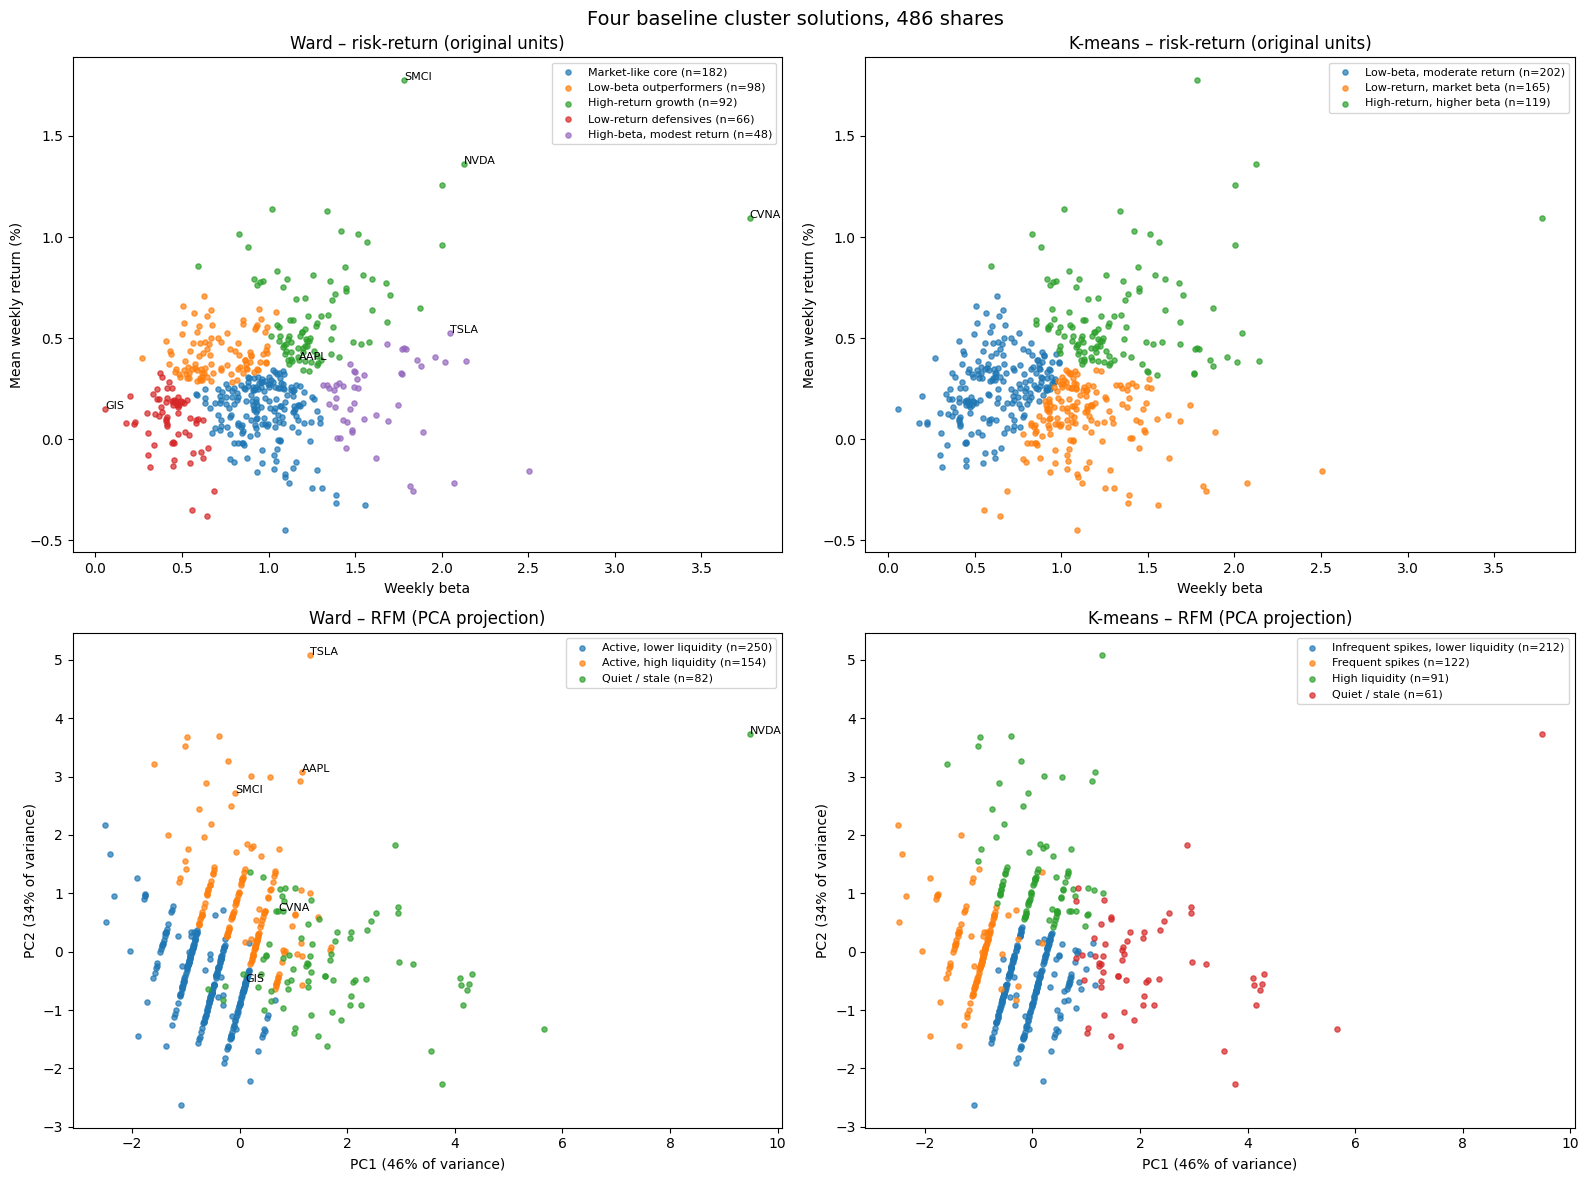

In [91]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEED)
rfm_2d = pd.DataFrame(pca.fit_transform(Z_rfm), index=common.index, columns=["PC1", "PC2"])
ev = pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_.T, index=Z_rfm.columns, columns=["PC1", "PC2"]).round(3)
print(f"PCA explained variance: PC1 {ev[0]:.1%}, PC2 {ev[1]:.1%}, total {ev.sum():.1%}")
print("Loadings (how each standardised feature contributes to each component):")
display(loadings)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
panels = [
    (axes[0, 0], "ward_rr",    orig["Beta"], orig["Return %/wk"], "Weekly beta", "Mean weekly return (%)", "Ward – risk-return (original units)"),
    (axes[0, 1], "kmeans_rr",  orig["Beta"], orig["Return %/wk"], "Weekly beta", "Mean weekly return (%)", "K-means – risk-return (original units)"),
    (axes[1, 0], "ward_rfm",   rfm_2d["PC1"], rfm_2d["PC2"], f"PC1 ({ev[0]:.0%} of variance)", f"PC2 ({ev[1]:.0%} of variance)", "Ward – RFM (PCA projection)"),
    (axes[1, 1], "kmeans_rfm", rfm_2d["PC1"], rfm_2d["PC2"], f"PC1 ({ev[0]:.0%} of variance)", f"PC2 ({ev[1]:.0%} of variance)", "K-means – RFM (PCA projection)"),
]
for ax, col, x, y, xl, yl, title in panels:
    for name in named[col].value_counts().index:
        m = named[col] == name
        ax.scatter(x[m], y[m], s=14, alpha=0.7, label=f"{name} (n={m.sum()})")
    ax.set(title=title, xlabel=xl, ylabel=yl)
    ax.legend(fontsize=8, loc="best")

# Label a few well-known or extreme shares for orientation
for t in ["NVDA", "TSLA", "AAPL", "SMCI", "CVNA", "GIS"]:
    if t in common.index:
        axes[0, 0].annotate(t, (orig.loc[t, "Beta"], orig.loc[t, "Return %/wk"]), fontsize=8)
        axes[1, 0].annotate(t, (rfm_2d.loc[t, "PC1"], rfm_2d.loc[t, "PC2"]), fontsize=8)

plt.suptitle(f"Four baseline cluster solutions, {len(common)} shares", fontsize=14)
plt.tight_layout()
plt.savefig("fig_2_4_cluster_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

Risk-return: selected Ward vs K-means  ARI = 0.396 | AMI = 0.509
RFM: selected Ward vs K-means  ARI = 0.318 | AMI = 0.398

Ward vs K-means at matched k:


ARI                AMI            
matrix    RFM Risk-return    RFM Risk-return
k                                           
3       0.834       0.516  0.749       0.533
4       0.343       0.265  0.432       0.392
5       0.401       0.329  0.521       0.503

kmeans_rr,"High-return, higher beta","Low-beta, moderate return","Low-return, market beta",Total
ward_rr,,,,
"High-beta, modest return",16,0,32,48
High-return growth,90,0,2,92
Low-beta outperformers,13,85,0,98
Low-return defensives,0,63,3,66
Market-like core,0,54,128,182


kmeans_rfm,Frequent spikes,High liquidity,"Infrequent spikes, lower liquidity",Quiet / stale,Total
ward_rfm,,,,,
"Active, high liquidity",14,84,52,4,154
"Active, lower liquidity",104,0,146,0,250
Quiet / stale,4,7,14,57,82


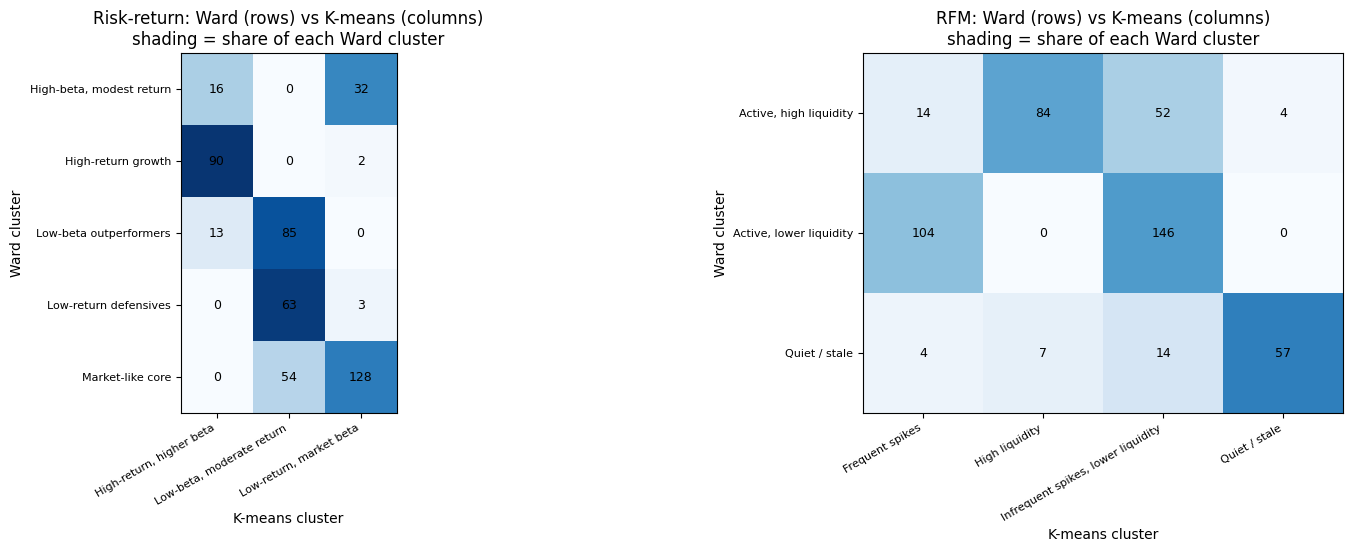

In [92]:
from sklearn.metrics import adjusted_mutual_info_score

# 1. Agreement between the selected solutions
for matrix, w, k in [("Risk-return", "ward_rr", "kmeans_rr"), ("RFM", "ward_rfm", "kmeans_rfm")]:
    ari = adjusted_rand_score(cluster_assignments[w], cluster_assignments[k])
    ami = adjusted_mutual_info_score(cluster_assignments[w], cluster_assignments[k])
    print(f"{matrix}: selected Ward vs K-means  ARI = {ari:.3f} | AMI = {ami:.3f}")

# 2. Like-for-like agreement at matched k (removes the effect of choosing different k)
rows = []
for k in [3, 4, 5]:
    for matrix, Z, L in [("Risk-return", Z_rr, L_rr), ("RFM", Z_rfm, L_rfm)]:
        w  = fcluster(L, k, "maxclust")
        km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit_predict(Z)
        rows.append({"matrix": matrix, "k": k,
                     "ARI": adjusted_rand_score(w, km), "AMI": adjusted_mutual_info_score(w, km)})
matched = pd.DataFrame(rows).pivot(index="k", columns="matrix", values=["ARI", "AMI"]).round(3)
print("\nWard vs K-means at matched k:")
display(matched)
matched.to_csv("algorithm_agreement_matched_k.csv")

# 3. Cross-tabulations of memberships (where shares move between algorithms)
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [5, 4]})
for ax, (matrix, w, k) in zip(axes, [("Risk-return", "ward_rr", "kmeans_rr"), ("RFM", "ward_rfm", "kmeans_rfm")]):
    ct = pd.crosstab(named[w], named[k])
    display(ct.assign(Total=ct.sum(axis=1)))
    ax.imshow(ct.div(ct.sum(axis=1), axis=0), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(ct.shape[1]), ct.columns, rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(ct.shape[0]), ct.index, fontsize=8)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            ax.text(j, i, ct.iloc[i, j], ha="center", va="center", fontsize=9)
    ax.set(title=f"{matrix}: Ward (rows) vs K-means (columns)\nshading = share of each Ward cluster",
           xlabel="K-means cluster", ylabel="Ward cluster")
plt.tight_layout()
plt.savefig("fig_2_4_algorithm_crosstabs.png", dpi=150, bbox_inches="tight")
plt.show()

## Task 2.5 – RFM sensitivity and correlated inputs

#### 2.5.1 Pearson and Spearman correlations among R, F and log1p(M); Spearman is included because R is heavily tied and F is discrete. To link correlation to clustering, the share of each feature’s variance explained by cluster membership (η²) shows which features actually drive each RFM solution.
####2.5.2 The selected Ward RFM solution (k = 3) is repeated using R and F only, on the same 486 shares, re-standardised from scratch. Memberships are compared with the adjusted Rand index, and traded-value profiles show whether M was mainly separating activity or liquidity levels.

Pearson correlation (linear):


,Recency,Frequency,log1p(Monetary)
Recency,1.000,-0.346,0.152
Frequency,-0.346,1.000,0.013
log1p(Monetary),0.152,0.013,1.000


Spearman correlation (rank-based, robust to ties and skew):


,Recency,Frequency,log1p(Monetary)
Recency,1.000,-0.196,0.137
Frequency,-0.196,1.000,-0.048
log1p(Monetary),0.137,-0.048,1.000


,Pearson r,p (Pearson),Spearman rho,p (Spearman)
pair,,,,
Recency – Frequency,-0.346,3.8e-15,-0.196,1.4e-05
Recency – log1p(Monetary),0.152,7.5e-04,0.137,2.4e-03
Frequency – log1p(Monetary),0.013,7.8e-01,-0.048,3.0e-01


Share of each standardised feature's variance explained by cluster membership (η²):


,Ward RFM (k=3),K-means RFM (k=4)
Recency_days,0.642,0.658
Frequency_60,0.119,0.570
log1p_Monetary,0.516,0.517


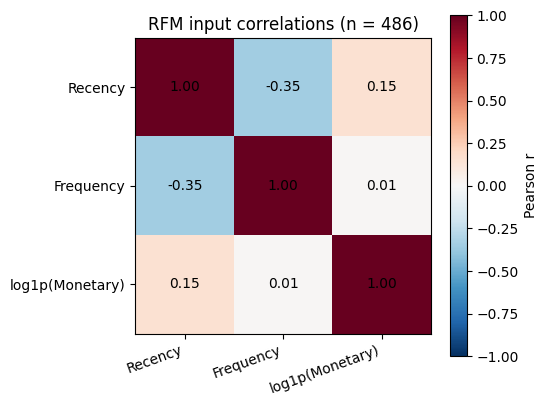

In [93]:
from scipy.stats import pearsonr, spearmanr

rfm_vars = pd.DataFrame({"Recency": common["Recency_days"],
                         "Frequency": common["Frequency_60"],
                         "log1p(Monetary)": np.log1p(common["Monetary_usd"])})

pearson  = rfm_vars.corr("pearson").round(3)
spearman = rfm_vars.corr("spearman").round(3)
print("Pearson correlation (linear):");  display(pearson)
print("Spearman correlation (rank-based, robust to ties and skew):"); display(spearman)

# Pairwise tests
pairs = []
for a, b in [("Recency", "Frequency"), ("Recency", "log1p(Monetary)"), ("Frequency", "log1p(Monetary)")]:
    r, pr = pearsonr(rfm_vars[a], rfm_vars[b])
    rho, ps = spearmanr(rfm_vars[a], rfm_vars[b])
    pairs.append({"pair": f"{a} – {b}", "Pearson r": round(r, 3), "p (Pearson)": f"{pr:.1e}",
                  "Spearman rho": round(rho, 3), "p (Spearman)": f"{ps:.1e}"})
pairs = pd.DataFrame(pairs).set_index("pair")
display(pairs)
pairs.to_csv("rfm_correlations.csv")

# Which features actually separate the clusters? eta-squared = between-cluster / total variance
def eta_squared(Z, labels):
    out = {}
    for c in Z.columns:
        total = ((Z[c] - Z[c].mean()) ** 2).sum()
        between = Z[c].groupby(labels).apply(lambda g: len(g) * (g.mean() - Z[c].mean()) ** 2).sum()
        out[c] = between / total
    return pd.Series(out)

eta = pd.DataFrame({"Ward RFM (k=3)":    eta_squared(Z_rfm, ward_rfm),
                    "K-means RFM (k=4)": eta_squared(Z_rfm, km_rfm)}).round(3)
print("Share of each standardised feature's variance explained by cluster membership (η²):")
display(eta)

# Heatmap
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(pearson, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(3), pearson.columns, rotation=20, ha="right")
ax.set_yticks(range(3), pearson.index)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{pearson.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title(f"RFM input correlations (n = {len(common)})")
plt.tight_layout()
plt.savefig("fig_2_5_rfm_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

Shares: 486 | k = 3 | R+F solution silhouette: 0.488
Full RFM vs R+F only:  ARI = 0.291 | AMI = 0.376


R+F-only cluster,1,2,3,Total
ward_rfm,,,,
"Active, high liquidity",9,59,86,154
"Active, lower liquidity",1,66,183,250
Quiet / stale,79,0,3,82


Full RFM Ward (k=3) – traded value by cluster:


,n,R median,F median,M median ($bn),M Q1 ($bn),M Q3 ($bn)
ward_rfm,,,,,,
"Active, high liquidity",154,11.0,3.0,39.70,28.22,68.39
"Active, lower liquidity",250,11.0,3.0,11.18,7.90,14.92
Quiet / stale,82,54.5,2.0,17.85,13.02,32.50


R+F-only Ward (k=3) – traded value by cluster:


,n,R median,F median,M median ($bn),M Q1 ($bn),M Q3 ($bn)
ward_rf_only,,,,,,
1,89,54.0,2.0,20.85,13.74,33.25
2,125,11.0,2.0,17.70,10.52,31.80
3,272,11.0,4.0,14.86,9.41,30.15


η² of log1p(M): full RFM solution = 0.516 | R+F-only solution = 0.004


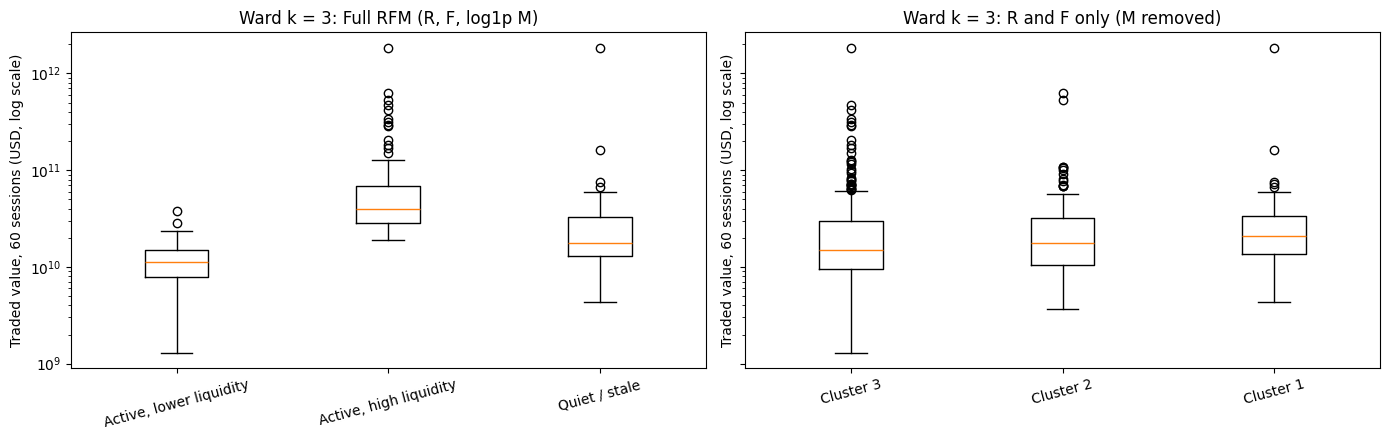

In [94]:
# Same shares, same k, R and F only, standardised AFRESH
X_rf = common[["Recency_days", "Frequency_60"]]
scaler_rf = StandardScaler()
Z_rf = pd.DataFrame(scaler_rf.fit_transform(X_rf), index=common.index, columns=X_rf.columns)

L_rf = linkage(Z_rf.values, method="ward", metric="euclidean")
ward_rf = pd.Series(fcluster(L_rf, K_WARD_RFM, "maxclust"), index=common.index, name="ward_rf_only")

assert ward_rf.index.equals(ward_rfm.index) and ward_rf.nunique() == K_WARD_RFM
print(f"Shares: {len(ward_rf)} | k = {K_WARD_RFM} | R+F solution silhouette: {silhouette_score(Z_rf, ward_rf):.3f}")
print(f"Full RFM vs R+F only:  ARI = {adjusted_rand_score(ward_rfm, ward_rf):.3f} | "
      f"AMI = {adjusted_mutual_info_score(ward_rfm, ward_rf):.3f}")

# Where do shares move?
ct = pd.crosstab(named["ward_rfm"], ward_rf.rename("R+F-only cluster"))
display(ct.assign(Total=ct.sum(axis=1)))

# Traded-value profiles: does M still differ across clusters once it is removed?
def tv_profile(labels):
    g = common.groupby(labels)
    return pd.DataFrame({
        "n":              g.size(),
        "R median":       g["Recency_days"].median(),
        "F median":       g["Frequency_60"].median(),
        "M median ($bn)": g["Monetary_usd"].median() / 1e9,
        "M Q1 ($bn)":     g["Monetary_usd"].quantile(0.25) / 1e9,
        "M Q3 ($bn)":     g["Monetary_usd"].quantile(0.75) / 1e9,
    }).round(2)

print("Full RFM Ward (k=3) – traded value by cluster:");  display(tv_profile(named["ward_rfm"]))
print("R+F-only Ward (k=3) – traded value by cluster:");  display(tv_profile(ward_rf))

log_m = np.log1p(common["Monetary_usd"]).to_frame("log1p(M)")
print(f"η² of log1p(M): full RFM solution = {eta_squared(log_m, ward_rfm).iloc[0]:.3f} | "
      f"R+F-only solution = {eta_squared(log_m, ward_rf).iloc[0]:.3f}")

# Figure: traded value by cluster, before and after removing M
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, lab, title in [(axes[0], named["ward_rfm"], "Full RFM (R, F, log1p M)"),
                       (axes[1], ward_rf.astype(str).radd("Cluster "), "R and F only (M removed)")]:
    order = lab.value_counts().index
    ax.boxplot([common.loc[lab == c, "Monetary_usd"] for c in order], tick_labels=order)
    ax.set_yscale("log")
    ax.set(title=f"Ward k = {K_WARD_RFM}: {title}", ylabel="Traded value, 60 sessions (USD, log scale)")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("fig_2_5_monetary_removal.png", dpi=150, bbox_inches="tight")
plt.show()

cluster_assignments["ward_rf_only"] = ward_rf
cluster_assignments.to_csv("cluster_assignments.csv")